# Aspect-Based Sentiment Analysis cho đánh giá điện thoại (UIT-ViSFD)

Notebook này **chỉ điều phối và trực quan hóa**. Toàn bộ logic nằm trong gói `src/absa`. Chạy được cả trên máy cá nhân lẫn **Google Colab** (*Runtime → Run all*).

## Quy trình (Run all chạy từ trên xuống dưới)

| Giai đoạn | Mục | Làm gì | Công tắc |
|---|---|---|---|
| **A. EDA** | 1–2 | Đọc dữ liệu, trực quan hóa nhãn, độ dài, xu hướng viết | – |
| **B. Xem xét tiền xử lý** | 3.1–3.4 | Minh họa từng bước, tác động lên từ vựng, **ablation** từng bước | `RUN_ABLATION` |
| **C. Chạy tiền xử lý** | 3.5 | Xử lý toàn bộ train/dev, lưu CSV | – |
| **D. Biểu diễn thưa × mô hình** | 4–5 | Nhiều loại sparse feature × nhiều mô hình ML × chiến lược | `FEATURES`, `MODELS`, `STRATEGIES` |
| **E. Thống kê kết quả** | 5.2–7 | Heatmap, bảng xếp hạng, so sánh chiến lược/biểu diễn/mô hình | – |
| **F. Phân tích lỗi** | 8–9 | Theo khía cạnh, 31 nhãn, confusion matrix, lỗi out-of-fold | `RUN_ERROR_ANALYSIS` |
| **G. Mô hình cuối** | 10–11 | Chọn mô hình tốt nhất, huấn luyện lại train+dev, test ẩn, đóng gói | – |

## Cách nhìn bài toán: 31 nhãn nhị phân (multilabel)

Mỗi bình luận có **31 nhãn nhị phân**: 10 khía cạnh × 3 cảm xúc (`BATTERY#Negative`, `BATTERY#Neutral`, `BATTERY#Positive`, ...) + `OTHERS`. Mỗi nhãn là một bài toán "có/không", nên mọi bộ phân loại nhị phân (LR, SVM, NB, ...) đều dùng được. Đây là chiến lược `multilabel` (Binary Relevance). Notebook **mặc định chạy cả 3 chiến lược** dưới đây để so sánh:

| Chiến lược | Cách làm | Số mô hình con |
|---|---|---|
| `multilabel` | 31 bộ phân loại nhị phân độc lập, rồi giải quyết xung đột (một khía cạnh không thể có 2 cảm xúc) | 31 |
| `joint` | mỗi khía cạnh một bộ phân loại 4 lớp `None/Neg/Neu/Pos` | 11 |
| `two_stage` | phát hiện khía cạnh, rồi phân cực trên các câu có nhắc khía cạnh đó | 21 |

## Cấu hình chạy

Notebook chỉ có **một cấu hình**: 6 biểu diễn × 3 mô hình × 3 chiến lược = 54 cấu hình.

- **6 biểu diễn cốt lõi**: `bow`, `tfidf_word`, `tfidf_word_char` (sparse) và `word2vec`, `fasttext`, `doc2vec` (static embedding).
- **3 mô hình ML cơ bản**: `logistic_regression`, `linear_svm`, `knn`. Không có cây/ensemble (Random Forest, boosting, XGBoost, AdaBoost...) và mạng nơ-ron.
- **3 chiến lược**: `multilabel`, `joint`, `two_stage`.

**Vì sao 6 biểu diễn này?** Mỗi biểu diễn trả lời một câu hỏi:
- `bow` so với `tfidf_word`: trọng số TF-IDF có hơn đếm thô không?
- `tfidf_word` so với `tfidf_word_char`: n-gram ký tự có thêm giá trị so với chỉ n-gram từ không? (Hai TF-IDF này cũng là hai TF-IDF điểm cao nhất ở các lượt thử trước: macro-F1 cặp trên dev với Logistic Regression `tfidf_word_char` 0,534; `tfidf_word` 0,530.)
- `word2vec`, `fasttext`, `doc2vec`: embedding đặc học trên train có thắng được túi từ thưa không? (Lượt thử trước cho Word2Vec/FastText chỉ khoảng 0,43, thấp hơn TF-IDF vì corpus nhỏ.)

Muốn thêm hay bớt thì sửa trực tiếp ba danh sách `FEATURES`, `MODELS`, `STRATEGIES` trong ô cấu hình bên dưới.

**Thời gian**: phần tốn thời gian chủ yếu là ablation, tinh chỉnh top-5 và việc học embedding (Word2Vec/FastText/Doc2Vec) (chưa đo trọn vẹn với bộ này). **Colab miễn phí chỉ có 2 CPU nên chậm hơn khoảng 4–6 lần** (ước tính). Muốn nhanh hơn: đặt `RUN_ABLATION = False` và `RUN_TUNING = False`.

## 0. Thiết lập 

In [1]:
import os
import subprocess
import sys
import zipfile
from pathlib import Path


# https://drive.google.com/file/d/14abAEBXzCzEHdmp_kasvmmQRjLhpcvhD/view?usp=drive_link
IN_COLAB = "google.colab" in sys.modules
GDRIVE_ZIP = "14abAEBXzCzEHdmp_kasvmmQRjLhpcvhD"          # <-- Colab: link chia sẻ Google Drive HOẶC file-id của file zip project
CONTENT = Path("/content")


def find_project_root(*starts):
    # Tìm thư mục chứa src/absa (chính nó, cha của nó hoặc thư mục con trực tiếp).
    for start in starts:
        start = Path(start).resolve()
        candidates = [start, *start.parents, *sorted(p for p in start.glob("*") if p.is_dir())]
        for cand in candidates:
            if (cand / "src" / "absa" / "__init__.py").exists():
                return cand
    return None


def pip_install_one_by_one(requirements_file):
    # Cài từng gói một: một gói lỗi chỉ báo cảnh báo, không làm hỏng cả quá trình.
    for line in Path(requirements_file).read_text(encoding="utf-8").splitlines():
        package = line.split("#")[0].strip()
        if not package:
            continue
        result = subprocess.run([sys.executable, "-m", "pip", "install", "-q", package],
                                capture_output=True, text=True)
        print(("OK       " if result.returncode == 0 else "CẢNH BÁO ") + package)


if IN_COLAB:
    root = find_project_root(CONTENT)
    if root is None:
        assert GDRIVE_ZIP, "Hãy dán link/file-id Google Drive của file zip vào GDRIVE_ZIP ở trên."
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True)
        import gdown

        zip_path = CONTENT / "project.zip"
        if GDRIVE_ZIP.startswith("http"):
            gdown.download(GDRIVE_ZIP, str(zip_path), quiet=False, fuzzy=True)
        else:
            gdown.download(id=GDRIVE_ZIP, output=str(zip_path), quiet=False)
        with zipfile.ZipFile(zip_path) as archive:
            archive.extractall(CONTENT)
        root = find_project_root(CONTENT)
        assert root is not None, "Không tìm thấy src/absa sau khi giải nén - kiểm tra lại file zip."
    os.chdir(root)
    pip_install_one_by_one(root / "requirements-colab.txt")
    print("Project:", root)
else:
    print("Chạy trên máy cá nhân - bỏ qua bước tải zip.")

Downloading...
From: https://drive.google.com/uc?id=14abAEBXzCzEHdmp_kasvmmQRjLhpcvhD
To: /content/project.zip
100%|██████████| 1.24M/1.24M [00:00<00:00, 147MB/s]


OK       underthesea
OK       pyvi
OK       gensim
OK       sentence-transformers
OK       wordcloud
Project: /content/absa-visfd


## 0.1 Thiết lập môi trường và cấu hình chạy

In [2]:
import warnings

ROOT = find_project_root(Path.cwd(), CONTENT if IN_COLAB else Path.cwd())
assert ROOT is not None, "Hãy mở notebook trong thư mục project (cần thấy src/absa)."
SRC = ROOT / "src"
sys.path.insert(0, str(SRC))
# Tiến trình con (joblib/loky) cần thấy gói absa khi fit song song các khía cạnh.
os.environ["PYTHONPATH"] = os.pathsep.join([str(SRC), os.environ.get("PYTHONPATH", "")])
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from absa.config import PATHS, PRIMARY_METRIC, SEED
from absa.utils import ensure_dir, save_json, set_seed
from absa.visualization import eda_plots, result_plots, save_figure, set_style

set_seed(SEED)
set_style()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
for d in (PATHS.reports_dir, PATHS.figures_dir, PATHS.models_dir):
    ensure_dir(d)
print("Project root:", ROOT)

import importlib.util

if importlib.util.find_spec("underthesea") is None:
    print("CẢNH BÁO: chưa cài underthesea -> bước chuẩn hóa dấu thanh chỉ dùng NFC, "
          "kết quả tiền xử lý sẽ lệch nhẹ so với bản gốc. Chạy: pip install underthesea")

Project root: /content/absa-visfd


### Cấu hình chạy

Lưới M x N lưu kết quả **từng dòng** vào CSV nên nếu bị ngắt, chạy lại sẽ tiếp tục từ chỗ dừng.

In [3]:
RUN_TUNING = True               # tinh chỉnh top-k sau vòng sàng lọc
TOP_K_TUNING = 5
RUN_ABLATION = True             # ablation tiền xử lý (mục 3.4)
RUN_ERROR_ANALYSIS = True       # dự đoán out-of-fold 5 fold trên train (mục 9)
RUN_DL = False                  # nhánh DL: bật khi có GPU
DL_MODELS = ["textcnn_fasttext"]  # thêm "phobert_base_v2", "visobert"... khi có GPU
INSPECT_DEV_TEXT = False        # KHÔNG đọc nội dung dev (xem mục 1)
SELECT_STRATEGY = None          # None = chọn mô hình tốt nhất trong mọi chiến lược;
                                # "multilabel" = chỉ chọn trong chiến lược 31 nhãn (để dùng predict_pairs)
N_JOBS = -1

FEATURES = ["bow", "tfidf_word", "tfidf_word_char", "word2vec", "fasttext", "doc2vec"]
MODELS = ["logistic_regression", "linear_svm", "knn"]
STRATEGIES = ("multilabel", "joint", "two_stage")
RESULTS_PATH = PATHS.reports_dir / "ml_grid.csv"
print(f"{len(FEATURES)} biểu diễn x {len(MODELS)} mô hình x {len(STRATEGIES)} chiến lược")
print("Biểu diễn :", FEATURES)
print("Mô hình   :", MODELS)
print("Chiến lược:", STRATEGIES)

6 biểu diễn x 3 mô hình x 3 chiến lược
Biểu diễn : ['bow', 'tfidf_word', 'tfidf_word_char', 'word2vec', 'fasttext', 'doc2vec']
Mô hình   : ['logistic_regression', 'linear_svm', 'knn']
Chiến lược: ('multilabel', 'joint', 'two_stage')


## 1. Bài toán và dữ liệu

**Bài toán.** Cho một bình luận về điện thoại, xác định (1) các **khía cạnh** được nhắc tới trong 10 khía cạnh `SCREEN, CAMERA, FEATURES, BATTERY, PERFORMANCE, STORAGE, DESIGN, PRICE, GENERAL, SER&ACC` (+ `OTHERS`), và (2) **cảm xúc** `Positive / Neutral / Negative` cho từng khía cạnh. Một bình luận có thể nhắc nhiều khía cạnh với cảm xúc trái ngược nhau.

**Biểu diễn nhãn.** Ma trận `Y` kích thước `(n, 11)`: mỗi cột một khía cạnh, giá trị `0 = không nhắc, 1 = Negative, 2 = Neutral, 3 = Positive` (OTHERS: 0/1). Từ `Y` suy ra hai nhiệm vụ để đánh giá:
- **Aspect detection**: đa nhãn nhị phân trên 11 khía cạnh.
- **Aspect sentiment**: đa nhãn trên 31 cặp `ASPECT#Polarity`. Một cặp chỉ đúng khi cả khía cạnh lẫn cảm xúc đều đúng.

**Loại bài toán.** Về bản chất là *multi-output multiclass* (11 đầu ra, mỗi đầu ra chọn 1 trong 4 lớp; một khía cạnh không thể có hai cảm xúc cùng lúc). Cách đơn giản nhất là trải thành **31 nhãn nhị phân** và dùng *multilabel classification* (chiến lược `multilabel`): mỗi nhãn một bộ phân loại độc lập, rồi giải quyết xung đột ở bước cuối. Nhược điểm đã biết của Binary Relevance là bỏ qua tương quan giữa các nhãn (Tsoumakas & Katakis, 2007), nên ta so sánh với `joint` và `two_stage`.

**Chính sách dùng các tập (chống rò rỉ thông tin).**

| Tập | Vai trò | Được phép |
|---|---|---|
| Train (7.786) | Học | EDA đầy đủ, thiết kế tiền xử lý, fit vectorizer/mô hình, cross-validation |
| Dev (1.112) | **Validation** | So sánh mô hình, tinh chỉnh, early stopping, ablation. Chỉ code đọc để tính metric; **không** đọc văn bản để đặt luật |
| Test (2.224) | **Hidden test** | Đánh giá **một lần** ở cuối với cấu hình đã chốt. Hiện file đang bị ẩn |

Lý do: test đã bị ẩn nên dev là ước lượng khách quan duy nhất còn lại. Nếu nhìn văn bản dev để đặt luật, điểm dev sẽ bị đẩy lên một cách ảo. Sau khi chọn xong mô hình, dev được gộp vào train để huấn luyện mô hình cuối.

In [4]:
from absa.data import label_frame, load_splits
from absa.preprocessing import PreparedCorpus, load_lexicons

splits = load_splits(include_test=True)
train, dev, test = splits["train"], splits["dev"], splits["test"]
corpus = PreparedCorpus({name: s.texts for name, s in splits.items() if s is not None})
labels = {name: s.labels for name, s in splits.items() if s is not None}
lexicons = load_lexicons()
print({name: (len(s) if s is not None else "hidden") for name, s in splits.items()})
display(train.frame.head(5))
display(pd.concat([train.frame[["comment"]].head(5), label_frame(train.labels[:5])], axis=1))

04:23:18 | INFO    | absa.data.loader | Không tìm thấy Test.csv – coi như tập 'test' đang bị ẩn.
{'train': 7786, 'dev': 1112, 'test': 'hidden'}


,index,comment,n_star,date_time,label
0,0,"Mới mua máy này Tại thegioididong thốt nốt cảm thấy ok bin trâu chụp ảnh đẹp loa nghe to bắt wf khỏe sóng ổn định, g...",5,2 tuần trước,{CAMERA#Positive};{FEATURES#Positive};{BATTERY#Positive};{PRICE#Positive};{GENERAL#Positive};{SER&ACC#Positive};
1,1,Pin kém còn lại miễn chê mua 8/3/2019 tình trạng pin còn 88% có ai giống tôi không,5,14/09/2019,{BATTERY#Negative};{GENERAL#Positive};{OTHERS};
2,2,Sao lúc gọi điện thoại màn hình bị chấm nhỏ nháy gần camera trước vậy(lúc có lúc không),3,17/08/2020,{FEATURES#Negative};
3,3,"Mọi người cập nhật phần mềm lại , nó sẽ bớt tốn pin, mình đã thử rồi, mọi thứ cũng ok, nhưng vân tay ko nhạy",3,29/02/2020,{FEATURES#Negative};{BATTERY#Neutral};{GENERAL#Neutral};
4,4,"Mới mua Sài được 1 tháng thấy pin rất trâu, Sài bao mượt . Nhưng có 1 lỗi nhỏ là mình nghe nhạc bằng tai nghe nghe h...",5,4/6/2020,{BATTERY#Positive};{PERFORMANCE#Positive};{SER&ACC#Negative};


,comment,SCREEN,CAMERA,FEATURES,BATTERY,PERFORMANCE,STORAGE,DESIGN,PRICE,GENERAL,SER&ACC,OTHERS
0,"Mới mua máy này Tại thegioididong thốt nốt cảm thấy ok bin trâu chụp ảnh đẹp loa nghe to bắt wf khỏe sóng ổn định, g...",-,Positive,Positive,Positive,-,-,-,Positive,Positive,Positive,-
1,Pin kém còn lại miễn chê mua 8/3/2019 tình trạng pin còn 88% có ai giống tôi không,-,-,-,Negative,-,-,-,-,Positive,-,Present
2,Sao lúc gọi điện thoại màn hình bị chấm nhỏ nháy gần camera trước vậy(lúc có lúc không),-,-,Negative,-,-,-,-,-,-,-,-
3,"Mọi người cập nhật phần mềm lại , nó sẽ bớt tốn pin, mình đã thử rồi, mọi thứ cũng ok, nhưng vân tay ko nhạy",-,-,Negative,Neutral,-,-,-,-,Neutral,-,-
4,"Mới mua Sài được 1 tháng thấy pin rất trâu, Sài bao mượt . Nhưng có 1 lỗi nhỏ là mình nghe nhạc bằng tai nghe nghe h...",-,-,-,Positive,Positive,-,-,-,-,Negative,-


## 2. Phân tích khám phá dữ liệu (EDA)

EDA chi tiết **chỉ trên train**. Với dev chỉ so sánh tỉ lệ nhãn ở mức tổng hợp (mục 2.4) để kiểm tra hai tập cùng phân phối.

### 2.1 Tổng quan

In [5]:
from absa import eda

display(eda.dataset_overview(splits))

,status,n_comments,words_mean,words_median,words_p95,words_max,aspects_per_comment,duplicate_comments,empty_comments
split,,,,,,,,,
train,available,7786.0,36.3,30.0,78.0,194.0,3.28,0.0,0.0
dev,available,1112.0,35.1,29.0,75.0,143.0,3.21,0.0,0.0
test,hidden,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.2 Nhãn: phân bố, mất cân bằng, đồng xuất hiện

,Negative,Neutral,Positive,Present,total,pct_comments
aspect,,,,,,
GENERAL,949,290,3627,0,4866,62.50
PERFORMANCE,1496,391,2253,0,4140,53.17
BATTERY,1228,349,2027,0,3604,46.29
FEATURES,1659,198,785,0,2642,33.93
CAMERA,627,288,1231,0,2146,27.56
PRICE,316,1136,609,0,2061,26.47
SER&ACC,487,107,1401,0,1995,25.62
OTHERS,0,0,0,1694,1694,21.76
DESIGN,302,77,999,0,1378,17.70


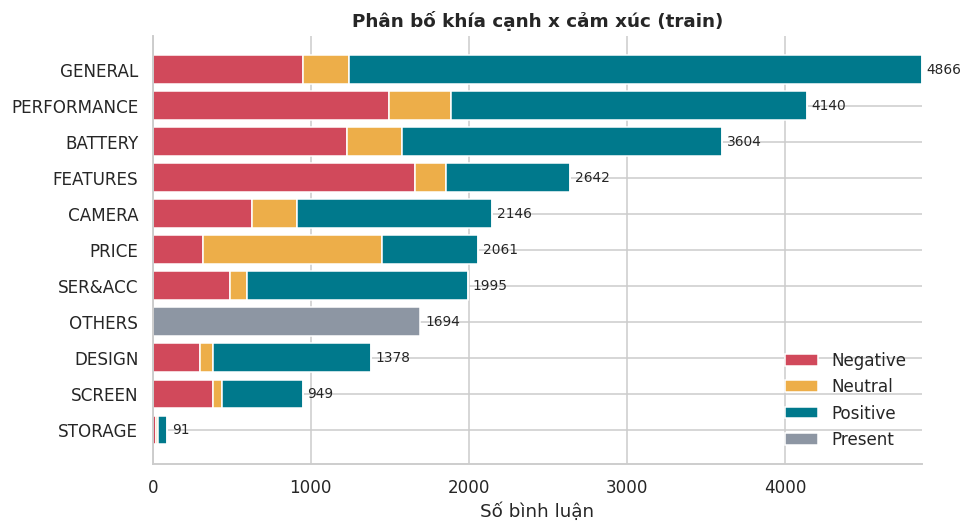

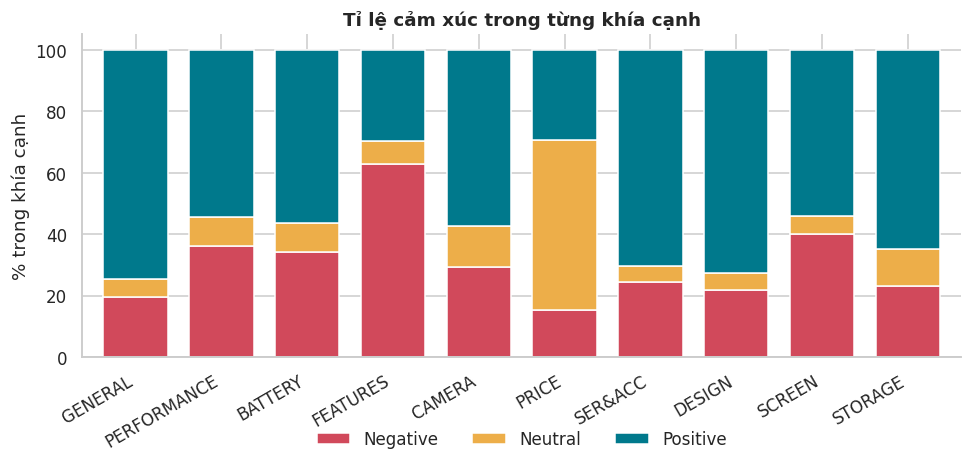

In [6]:
counts = eda.aspect_polarity_counts(train.labels)
display(counts)
fig = eda_plots.plot_aspect_polarity(counts); save_figure(fig, "eda_aspect_polarity"); plt.show()
fig = eda_plots.plot_polarity_share(counts); save_figure(fig, "eda_polarity_share"); plt.show()

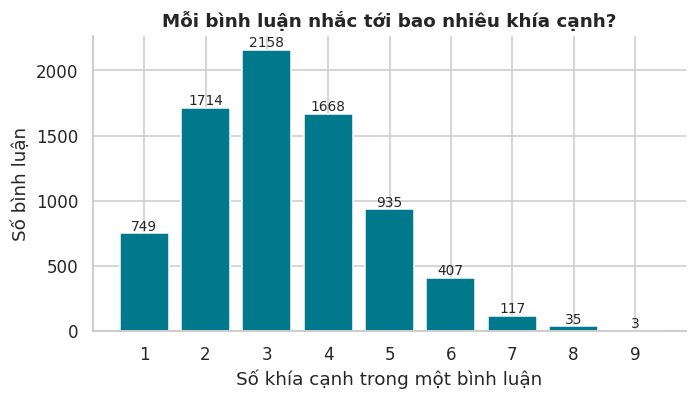

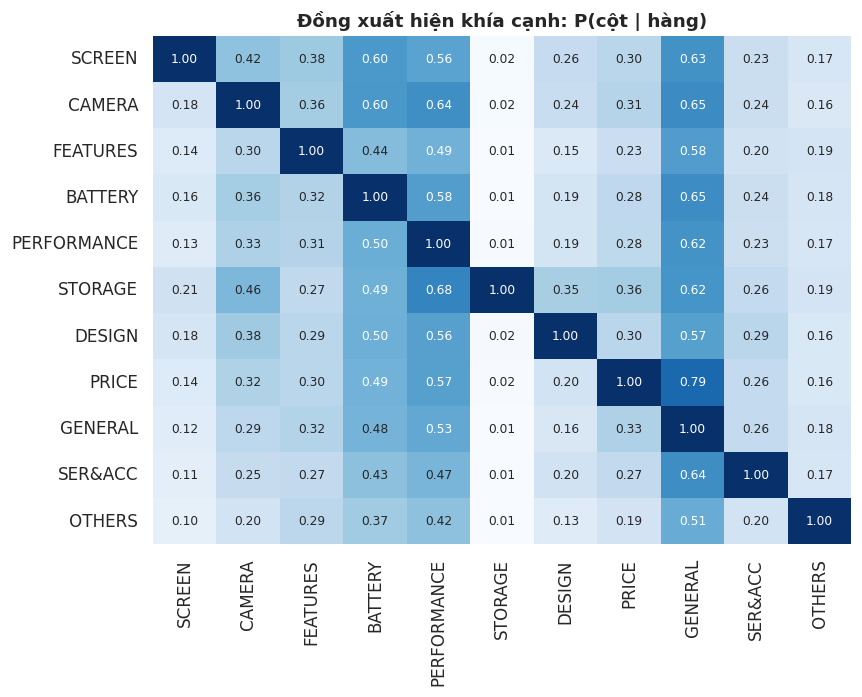

,%
pct_mixed_pos_neg,25.16
pct_multi_aspect,85.31
pct_single_polarity_multi_aspect,60.15


In [7]:
fig = eda_plots.plot_labels_per_comment(eda.labels_per_comment(train.labels)); save_figure(fig, "eda_labels_per_comment"); plt.show()
fig = eda_plots.plot_cooccurrence(eda.aspect_cooccurrence(train.labels)); save_figure(fig, "eda_cooccurrence"); plt.show()
display(pd.Series(eda.mixed_sentiment_rate(train.labels), name="%"))

,n_comments,Negative,Neutral,Positive
n_star,,,,
1,1271,86.9,6.6,6.6
2,567,73.7,11.1,15.2
3,1012,61.8,13.9,24.3
4,1266,28.4,17.1,54.5
5,3670,7.1,11.9,81.0


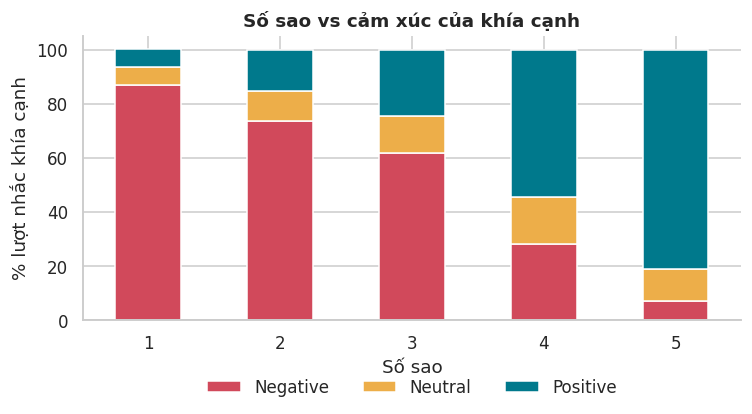

In [8]:
star_table = eda.star_polarity_crosstab(train.stars, train.labels)
display(star_table)
fig = eda_plots.plot_star_polarity(star_table); save_figure(fig, "eda_star_polarity"); plt.show()

**Nhận xét cần rút ra (điền sau khi chạy):**
- Mất cân bằng mạnh giữa các khía cạnh (GENERAL, PERFORMANCE nhiều; STORAGE rất hiếm) và bên trong khía cạnh (Neutral hiếm) → dùng `class_weight="balanced"`, chọn mô hình theo **macro-F1**.
- Đa số bình luận nhắc từ 2 khía cạnh trở lên, một phần đáng kể có cả cảm xúc tích cực lẫn tiêu cực → phải làm ABSA, không thể dùng một nhãn cảm xúc cho cả câu.
- Số sao chỉ phản ánh xu hướng chung (bình luận 5 sao vẫn có khía cạnh tiêu cực) → không dùng số sao làm nhãn hay đặc trưng.

### 2.3 Văn bản: độ dài và xu hướng viết

,count,mean,std,min,25%,50%,75%,max
n_chars,7786.0,159.657205,88.964386,10.0,98.0,129.0,190.0,850.0
n_words,7786.0,36.321731,20.325075,3.0,22.0,30.0,43.0,194.0


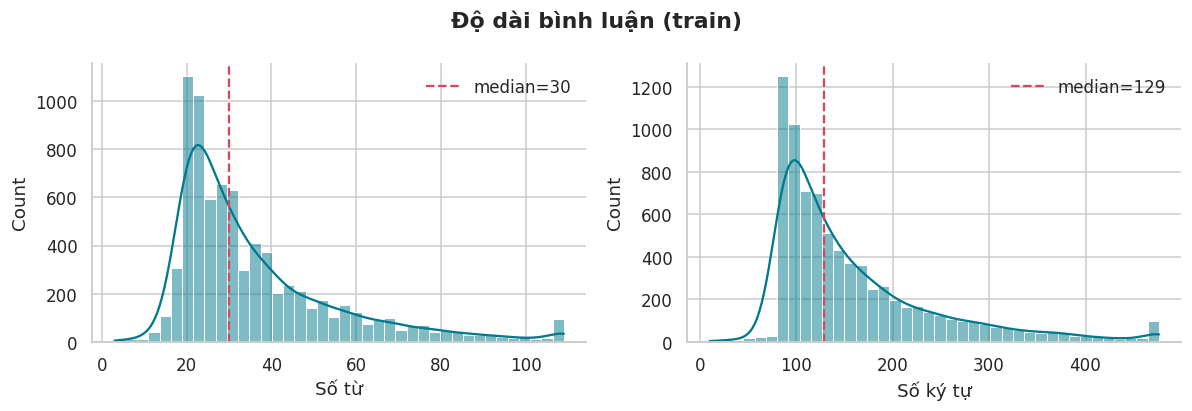

In [9]:
lengths = eda.text_length_frame(train.texts)
display(lengths.describe().T)
fig = eda_plots.plot_length_distribution(lengths); save_figure(fig, "eda_length"); plt.show()

,pattern,n_comments,pct_comments
0,teencode_in_lexicon,5149,66.13
1,any_digit,4866,62.50
2,number_with_unit,1539,19.77
3,repeated_punct,1114,14.31
4,line_break,895,11.49
5,allcaps_word,394,5.06
6,emoji,303,3.89
7,not_unicode_nfc,240,3.08
8,emoticon,149,1.91
9,char_elongation,58,0.74


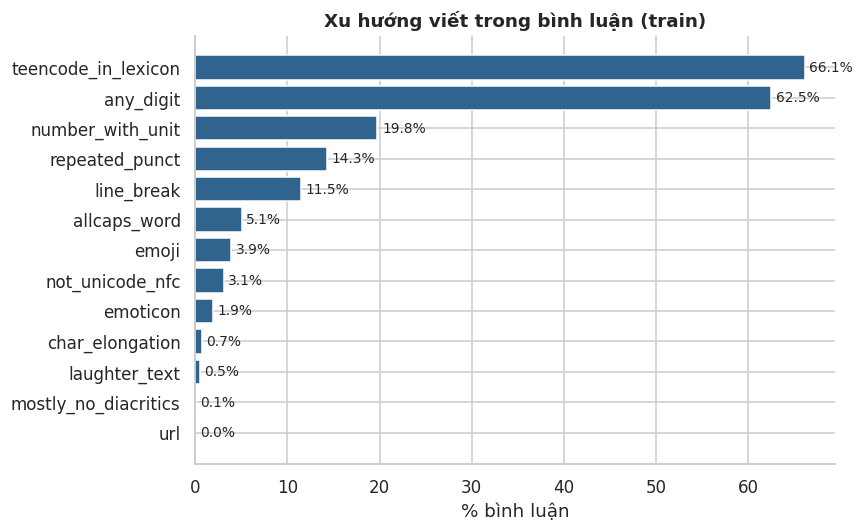

In [10]:
patterns = eda.text_pattern_report(train.texts, lexicons)
display(patterns)
fig = eda_plots.plot_text_patterns(patterns); save_figure(fig, "eda_text_patterns"); plt.show()

In [11]:
display(eda.emoji_frequency(train.texts, lexicons, top_n=25))
print(f"Tỉ lệ token không phải âm tiết tiếng Việt chuẩn: {eda.nonstandard_token_rate(train.texts)}%")
display(eda.nonstandard_token_report(train.texts, lexicons, top_n=50))

,emoji,count,unicode_name,category
0,👍,93,THUMBS UP SIGN,pos
1,😂,47,FACE WITH TEARS OF JOY,pos
2,🥰,34,SMILING FACE WITH SMILING EYES AND THREE HEARTS,pos
3,😍,34,SMILING FACE WITH HEART-SHAPED EYES,pos
4,😁,33,GRINNING FACE WITH SMILING EYES,pos
5,😭,32,LOUDLY CRYING FACE,neg
6,♥,32,BLACK HEART SUIT,pos
7,👌,31,OK HAND SIGN,pos
8,❤,25,HEAVY BLACK HEART,pos
9,😑,21,EXPRESSIONLESS FACE,neg


Tỉ lệ token không phải âm tiết tiếng Việt chuẩn: 9.03%


,token,count,in_teencode_lexicon
0,game,2222,False
1,ok,1965,True
2,k,1418,True
3,camera,1395,False
4,đc,1039,True
5,lag,553,False
6,wifi,520,False
7,dc,502,True
8,g,470,False
9,đt,459,True


Bảng trên được dùng để **kiểm tra độ phủ của từ điển một cách có hệ thống**, không để sửa từng câu:
- Token có `in_teencode_lexicon = True` (`ko`, `k`, `dc`, `đt`, `nv`, ...) đã được chuẩn hóa.
- Token còn lại phần lớn là thuật ngữ/thương hiệu (`camera`, `game`, `wifi`, `samsung`, `pubg`) → **giữ nguyên** vì chúng mang thông tin khía cạnh.
- Dạng viết không có trong từ điển vẫn được che chắn bởi luật tổng quát (rút gọn ký tự lặp, `-g` → `-ng`) và bởi TF-IDF n-gram ký tự / FastText subword.

### 2.4 Kiểm tra phân phối dev (chỉ số liệu tổng hợp, không đọc văn bản)

,train,dev,diff_pp
SCREEN,12.19,10.88,-1.31
CAMERA,27.56,26.62,-0.94
FEATURES,33.93,34.26,0.33
BATTERY,46.29,45.32,-0.97
PERFORMANCE,53.17,52.34,-0.83
STORAGE,1.17,1.26,0.09
DESIGN,17.70,16.82,-0.88
PRICE,26.47,22.66,-3.81
GENERAL,62.50,61.96,-0.54
SER&ACC,25.62,26.08,0.46


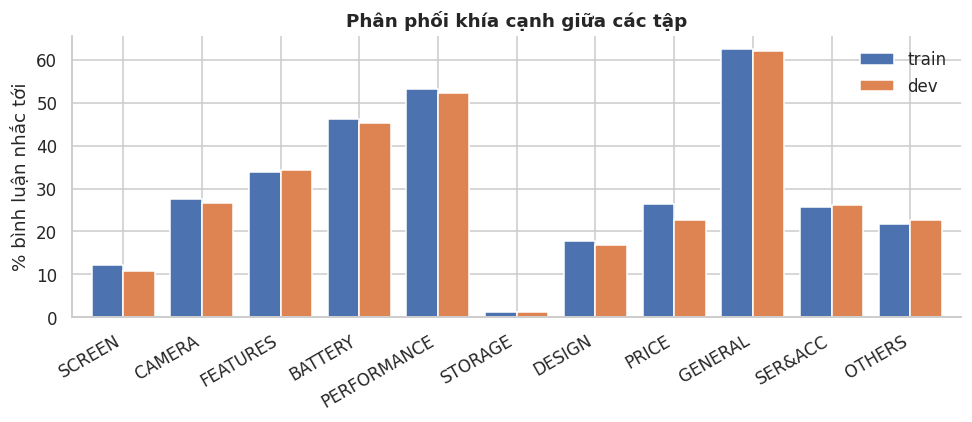

In [12]:
shift = eda.label_distribution_shift({name: labels.get(name) for name in ("train", "dev")})
shift["diff_pp"] = shift["dev"] - shift["train"]
display(shift)
fig = eda_plots.plot_split_shift(shift[["train", "dev"]]); save_figure(fig, "eda_split_shift"); plt.show()

### 2.5 Từ EDA đến quyết định thiết kế

| Quan sát trên train | Quyết định |
|---|---|
| Nhiều khía cạnh / câu, cảm xúc trái chiều | Mô hình đa đầu ra theo khía cạnh: 31 nhãn nhị phân (`multilabel`) hoặc theo từng khía cạnh (`joint`, `two_stage`) |
| Mất cân bằng lớp mạnh | `class_weight`, metric chính là macro-F1, báo cáo kèm micro-F1 |
| Teencode/viết tắt, tiếng cười, kéo dài ký tự, thiếu `n` trong `-ng` | Luật chuẩn hóa tổng quát + từ điển đã kiểm định (mục 3) |
| Emoji/emoticon mang cảm xúc | Gom về 3 nhãn cảm xúc, có luật dự phòng theo tên Unicode cho emoji chưa gặp |
| Số + đơn vị (`5000mah`, `7tr`, `128gb`) gắn với khía cạnh | Thay bằng token theo **loại đơn vị** thay vì xóa số |
| Xuống dòng thay dấu câu | Đổi xuống dòng thành ranh giới câu trước khi tách từ |
| Từ ghép đa âm tiết (`màn hình`) | Thử tách từ tiếng Việt và để ablation quyết định (mục 3.4) |
| Phủ định đảo cảm xúc (`không mượt`) | Gắn phủ định với từ theo sau |

## 3. Tiền xử lý

Mọi bước là **luật tổng quát** (regex theo chính tả tiếng Việt, từ điển có thể đọc và sửa trong `resources/lexicons`), áp dụng giống hệt cho train, dev, test và bình luận mới khi triển khai. Bộ tiền xử lý không học gì từ dữ liệu.

**Cải tiến so với refs:**
- `wrong-word.txt` của refs **bị loại bỏ**: danh sách này xóa cả `pin`, `ok`, `game`, `camera`, `wifi`, `nhanh`, tức đúng những từ mang khía cạnh.
- Stopword của refs chứa `rất`, `quá`, `chưa`, `nhưng`, `được`, `nhanh`, `lâu`, ... nên chỉ dùng **sau khi trừ danh sách từ được bảo vệ** (`protected_words.txt`), và chỉ bật nếu ablation cho thấy có lợi.
- Teencode của refs được lọc các mục sai hoặc mơ hồ trong domain điện thoại (`note`→`chú ý` làm hỏng *Galaxy Note*, `face`→`facebook` làm hỏng *face ID*), rồi bổ sung văn phong review điện thoại.
- Thêm các bước mới: số + đơn vị, emoji có luật dự phòng, emoticon, tiếng cười/khóc, `-g`→`-ng`, xuống dòng, gắn phủ định.

### 3.1 Minh họa từng bước trên một câu

In [13]:
from absa.preprocessing import PREPROCESS_PROFILES, TextPreprocessor

demo = "Pin trâu 5000mAh 👍👍, chơi game ko lag tí nào =)) nhưng cam chụp đêm hơi mờ\nGiá 7tr5 khôg rẻ lắm, nv tư vấn nhiệt tìnhhhh"
display(TextPreprocessor("classic").trace(demo))
for name in PREPROCESS_PROFILES:
    print(f"{name:16s} -> {TextPreprocessor(name).process(demo)}")

,step,output,changed
0,input,"Pin trâu 5000mAh 👍👍, chơi game ko lag tí nào =)) nhưng cam chụp đêm hơi mờ\nGiá 7tr5 khôg rẻ lắm, nv tư vấn nhiệt tì...",False
1,line_breaks,"Pin trâu 5000mAh 👍👍, chơi game ko lag tí nào =)) nhưng cam chụp đêm hơi mờ . Giá 7tr5 khôg rẻ lắm, nv tư vấn nhiệt t...",True
2,remove_urls,"Pin trâu 5000mAh 👍👍, chơi game ko lag tí nào =)) nhưng cam chụp đêm hơi mờ . Giá 7tr5 khôg rẻ lắm, nv tư vấn nhiệt t...",False
3,emoji,"Pin trâu 5000mAh emopos , chơi game ko lag tí nào =)) nhưng cam chụp đêm hơi mờ . Giá 7tr5 khôg rẻ lắm, nv tư vấn n...",True
4,emoticon,"Pin trâu 5000mAh emopos , chơi game ko lag tí nào emopos nhưng cam chụp đêm hơi mờ . Giá 7tr5 khôg rẻ lắm, nv tư ...",True
5,unicode,"Pin trâu 5000mAh emopos , chơi game ko lag tí nào emopos nhưng cam chụp đêm hơi mờ . Giá 7tr5 khôg rẻ lắm , nv tư vấ...",True
6,lowercase,"pin trâu 5000mah emopos , chơi game ko lag tí nào emopos nhưng cam chụp đêm hơi mờ . giá 7tr5 khôg rẻ lắm , nv tư vấ...",True
7,laughter,"pin trâu 5000mah emopos , chơi game ko lag tí nào emopos nhưng cam chụp đêm hơi mờ . giá 7tr5 khôg rẻ lắm , nv tư vấ...",False
8,numbers,"pin trâu numbattery emopos , chơi game ko lag tí nào emopos nhưng cam chụp đêm hơi mờ . giá numprice khôg rẻ lắm...",True
9,elongation,"pin trâu numbattery emopos , chơi game ko lag tí nào emopos nhưng cam chụp đêm hơi mờ . giá numprice khôg rẻ lắm , n...",True


classic          -> pin trâu numbattery emopos chơi game không_lag tí nào emopos nhưng cam chụp đêm hơi mờ giá numprice không_rẻ lắm nhân viên tư vấn nhiệt tình
classic_seg      -> pin trâu numbattery emopos chơi game không_lag_tí nào emopos nhưng cam chụp đêm hơi mờ giá numprice không_rẻ lắm nhân_viên tư_vấn nhiệt_tình
transformer_seg  -> pin trâu 5000 mah vui , chơi game không lag_tí nào vui nhưng cam chụp đêm hơi mờ . giá 7 tr5 không rẻ lắm , nhân_viên tư_vấn nhiệt_tình
transformer_raw  -> pin trâu 5000mah 👍 👍 , chơi game không lag tí nào vui nhưng cam chụp đêm hơi mờ . giá 7tr5 không rẻ lắm , nhân viên tư vấn nhiệt tình


### 3.2 Áp dụng cho các tập và đo tác động lên từ vựng

04:23:41 | INFO    | absa.preprocessing.pipeline | Tiền xử lý tập 'train' (7786 câu)...


preprocess:   0%|          | 0/7786 [00:00<?, ?it/s]

04:23:47 | INFO    | absa.preprocessing.pipeline | Tiền xử lý tập 'dev' (1112 câu)...


preprocess:   0%|          | 0/1112 [00:00<?, ?it/s]

,raw (lower+split),processed,change_%
n_tokens,282801.00,276179.00,-2.3
vocab_size,15381.00,6827.00,-55.6
hapax,9633.00,3151.00,-67.3
tokens_per_comment,36.32,35.47,-2.3


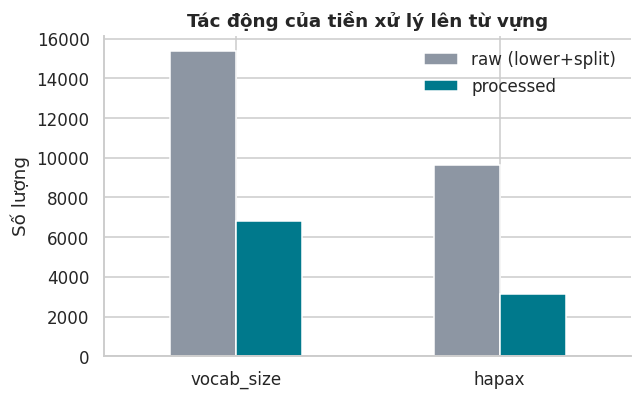

,raw,classic
0,"Mới mua máy này Tại thegioididong thốt nốt cảm thấy ok bin trâu chụp ảnh đẹp loa nghe to bắt wf khỏe sóng ổn định, g...",mới mua máy này tại thế giới di động thốt nốt cảm thấy ok pin trâu chụp ảnh đẹp loa nghe to bắt wifi khỏe sóng ổn đị...
1,Pin kém còn lại miễn chê mua 8/3/2019 tình trạng pin còn 88% có ai giống tôi không,pin kém còn lại miễn chê mua numdate tình trạng pin còn numpercent có ai giống tôi không
2,Sao lúc gọi điện thoại màn hình bị chấm nhỏ nháy gần camera trước vậy(lúc có lúc không),sao lúc gọi điện thoại màn hình bị chấm nhỏ nháy gần camera trước vậy lúc có lúc không
3,"Mọi người cập nhật phần mềm lại , nó sẽ bớt tốn pin, mình đã thử rồi, mọi thứ cũng ok, nhưng vân tay ko nhạy",mọi người cập nhật phần mềm lại nó sẽ bớt tốn pin mình đã thử rồi mọi thứ cũng ok nhưng vân tay không_nhạy
4,"Mới mua Sài được 1 tháng thấy pin rất trâu, Sài bao mượt . Nhưng có 1 lỗi nhỏ là mình nghe nhạc bằng tai nghe nghe h...",mới mua xài được numduration thấy pin rất trâu xài bao mượt nhưng có num lỗi nhỏ là mình nghe nhạc bằng tai nghe ngh...
5,"Xài tốt, rất mượt, pin trâu nếu các bạn để độ sáng vừa đủ, nhân viên nhiệt tình, vui vẻ, nói chung là tầm giá này th...",xài tốt rất mượt pin trâu nếu các bạn để độ sáng vừa đủ nhân viên nhiệt tình vui vẻ nói chung là tầm giá này thì máy...
6,Mình mới xài được 7 tháng xuống 7% pin. Chả hiểu máy mới kiểu gì nữa. Dùng cơ bản lướt web cơ bản game ko chơi,mình mới xài được numduration xuống numpercent pin chả_hiểu máy mới kiểu gì nữa dùng cơ bản lướt web cơ bản game khô...
7,"Hôm qua ngày 23/6/2020 e ra thế giới di động mua chiếc dthoai galaxy A51 ,. Lúc đầu bên cửa hàng báo giá 7.790.00đ ...",hôm qua ngày numdate e ra thế giới di động mua chiếc điện thoại galaxy a51 lúc đầu bên cửa hàng báo giá numprice đượ...


In [14]:
classic_train = corpus.get("classic", "train")
corpus.get("classic", "dev")
impact = eda.preprocessing_impact(train.texts, classic_train)
display(impact)
fig = eda_plots.plot_preprocessing_impact(impact); save_figure(fig, "prep_vocab_impact"); plt.show()
sample = pd.DataFrame({"raw": train.texts[:8], "classic": classic_train[:8]})
display(sample)

### 3.3 Từ đặc trưng theo khía cạnh sau tiền xử lý (chi²): kiểm tra token tạo ra có ý nghĩa

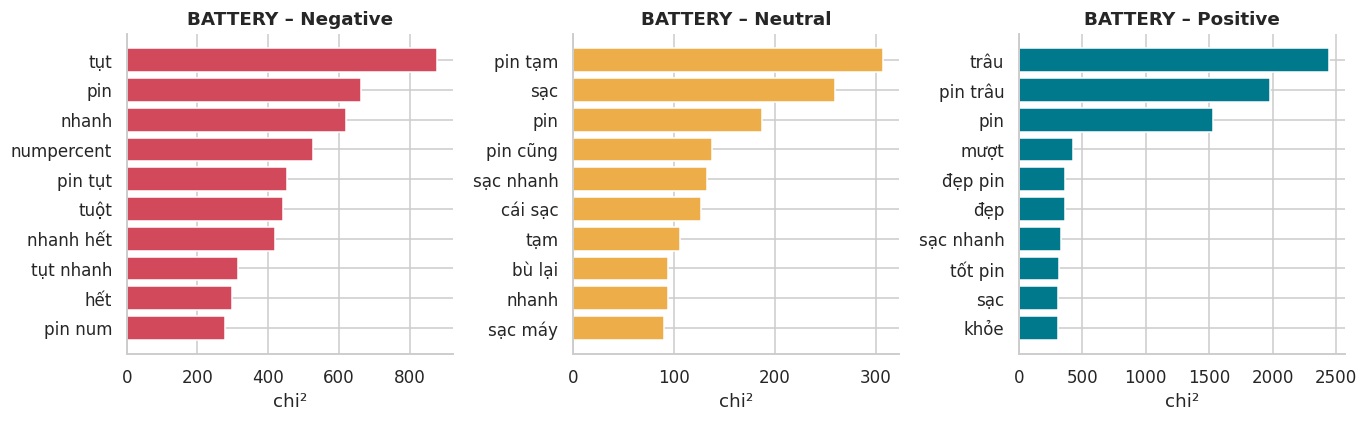

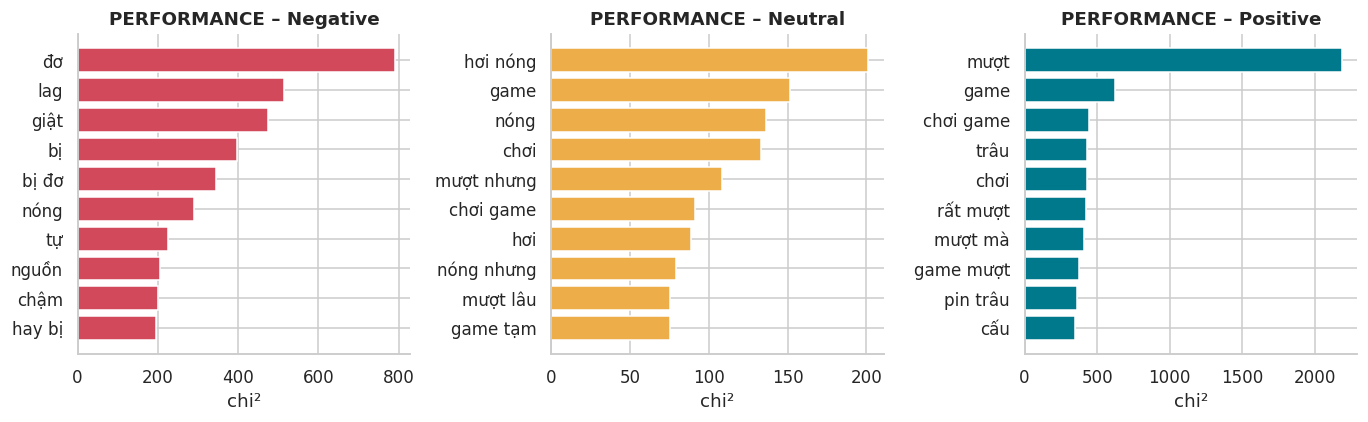

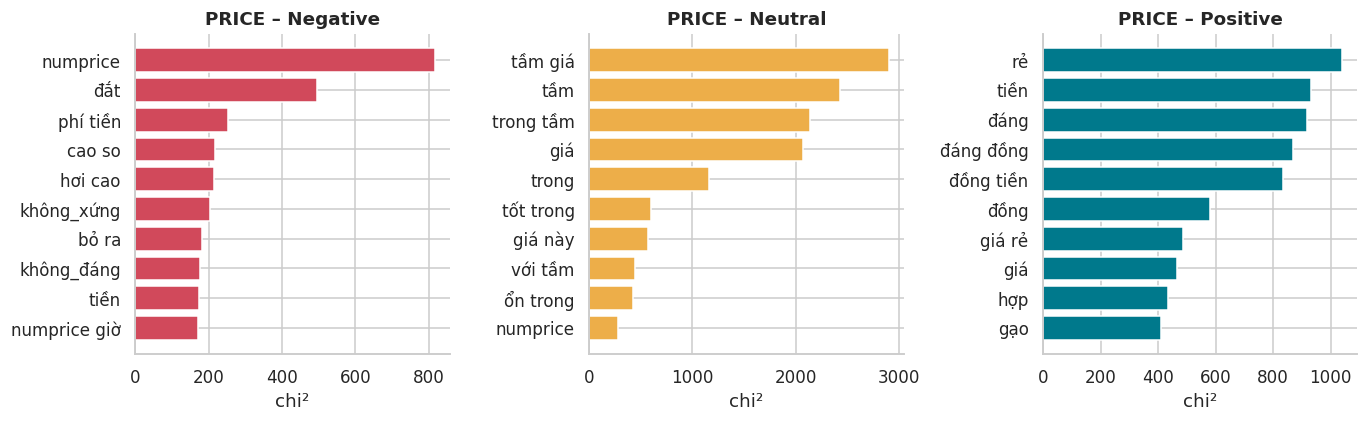

In [15]:
for aspect in ["BATTERY", "PERFORMANCE", "PRICE"]:
    terms = eda.top_terms_by_aspect(classic_train, train.labels, aspect, top_n=10)
    fig = eda_plots.plot_top_terms(terms, aspect); save_figure(fig, f"prep_top_terms_{aspect}"); plt.show()

### 3.4 Ablation: mỗi bước đóng góp bao nhiêu?

Cố định TF-IDF + Logistic Regression, chỉ thay cấu hình tiền xử lý và đo trên dev. Đây là phần **motivation định lượng** cho từng bước (yêu cầu 4.2 của đề).

04:23:59 | INFO    | absa.training.ablation | 0. minimal (lower + punct)     pair_f1_macro=0.4937 vocab=6519
04:24:06 | INFO    | absa.training.ablation | 1. + unicode/tone              pair_f1_macro=0.5008 vocab=6205
04:24:15 | INFO    | absa.training.ablation | 2. + emoji/emoticon tags       pair_f1_macro=0.4980 vocab=6185
04:24:24 | INFO    | absa.training.ablation | 3. + number/unit tokens        pair_f1_macro=0.4998 vocab=5586
04:24:33 | INFO    | absa.training.ablation | 4. + elongation                pair_f1_macro=0.4982 vocab=5550
04:24:43 | INFO    | absa.training.ablation | 5. + teencode & final-ng       pair_f1_macro=0.4973 vocab=5363
04:24:47 | INFO    | absa.training.ablation | 6. + negation (= classic)      pair_f1_macro=0.4995 vocab=6827
04:25:12 | INFO    | absa.training.ablation | 7. classic + word segmentation pair_f1_macro=0.4878 vocab=11803
04:25:21 | INFO    | absa.training.ablation | 8. classic + stopword removal  pair_f1_macro=0.5020 vocab=6523
04:25:26 | INFO   

,pair_f1_macro,pair_f1_micro,aspect_f1_macro,vocab_size
variant,,,,
0. minimal (lower + punct),0.493712,0.718419,0.741677,6519
1. + unicode/tone,0.500816,0.721186,0.742394,6205
2. + emoji/emoticon tags,0.498008,0.719492,0.742878,6185
3. + number/unit tokens,0.499819,0.721603,0.744452,5586
4. + elongation,0.498174,0.721039,0.744084,5550
5. + teencode & final-ng,0.497289,0.723248,0.746077,5363
6. + negation (= classic),0.499469,0.724569,0.744698,6827
7. classic + word segmentation,0.487752,0.701501,0.735848,11803
8. classic + stopword removal,0.502043,0.715991,0.742892,6523


,pair_f1_macro,pair_f1_micro,aspect_f1_macro,vocab_size
variant,,,,
classic (full),0.499469,0.724569,0.744698,6827
- unicode/tone,0.496386,0.720609,0.746631,7171
- emoji/emoticon tags,0.499097,0.725664,0.746356,6822
- number/unit tokens,0.498145,0.724036,0.742590,7443
- elongation,0.497504,0.724002,0.744868,6863
- teencode & final-ng,0.500733,0.721330,0.748877,6597
- negation,0.497289,0.723248,0.746077,5363
+ word segmentation,0.487752,0.701501,0.735848,11803
+ stopword removal,0.502043,0.715991,0.742892,6523


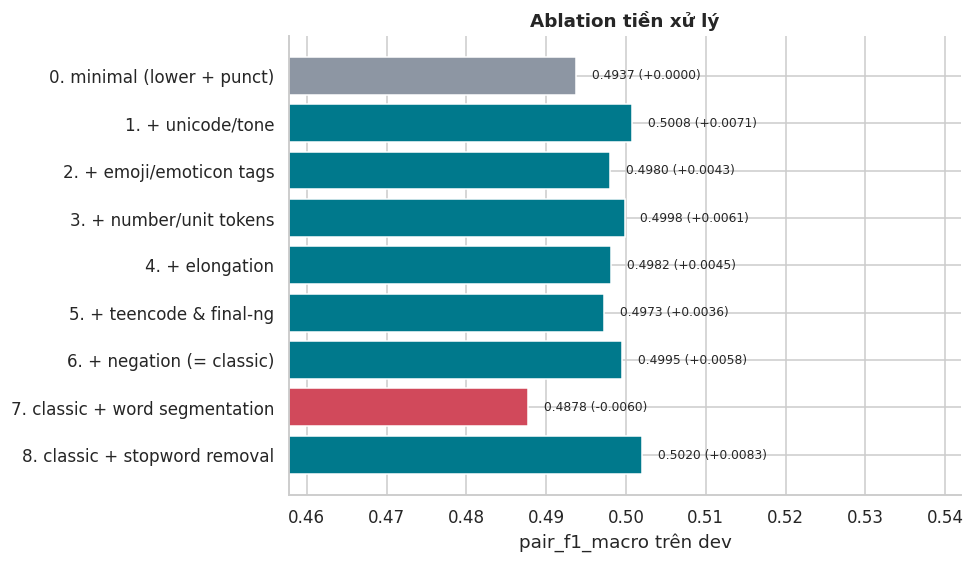

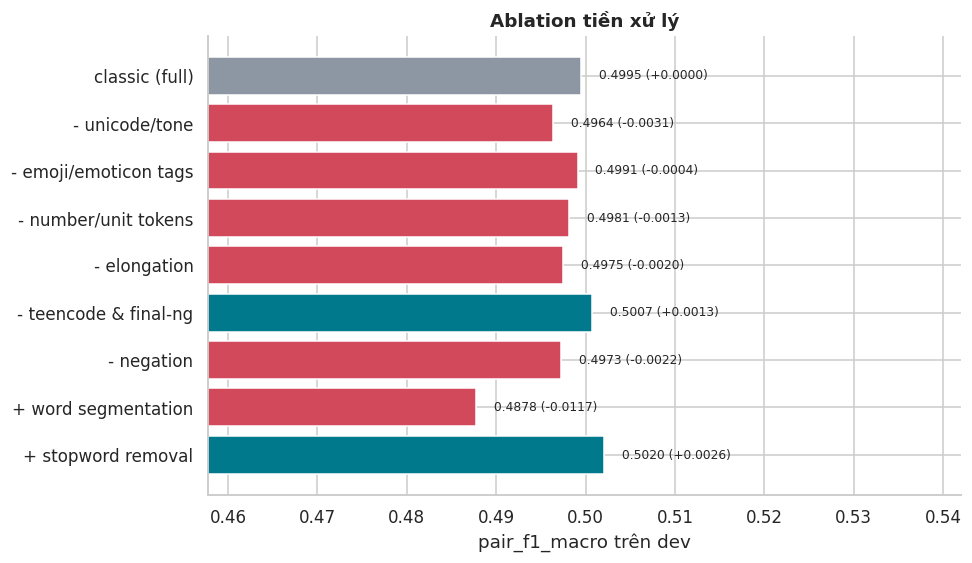

In [16]:
from absa.training import cumulative_variants, leave_one_out_variants, run_preprocessing_ablation

if RUN_ABLATION:
    ablation_cum = run_preprocessing_ablation(
        train.texts, train.labels, dev.texts, dev.labels, cumulative_variants(), n_jobs=N_JOBS
    )
    ablation_loo = run_preprocessing_ablation(
        train.texts, train.labels, dev.texts, dev.labels, leave_one_out_variants(), n_jobs=N_JOBS
    )
    ablation_cum.to_csv(PATHS.reports_dir / "ablation_cumulative.csv")
    ablation_loo.to_csv(PATHS.reports_dir / "ablation_leave_one_out.csv")
    cols = [PRIMARY_METRIC, "pair_f1_micro", "aspect_f1_macro", "vocab_size"]
    display(ablation_cum[cols]); display(ablation_loo[cols])
    fig = result_plots.plot_ablation(ablation_cum); save_figure(fig, "ablation_cumulative"); plt.show()
    fig = result_plots.plot_ablation(ablation_loo); save_figure(fig, "ablation_leave_one_out"); plt.show()

**Cách đọc:** dòng `- X` là bỏ bước X khỏi `classic`; dòng `+ X` là thêm bước X (chưa có trong `classic`). Điểm *giảm* khi bỏ một bước nghĩa là bước đó có ích.

**Kết quả lượt chạy đầu tiên (đo với chiến lược `joint`, trước khi sửa lỗi gắn phủ định qua ranh giới câu; dùng để chốt cấu hình, chạy lại với `multilabel` và bản đã sửa có thể lệch nhẹ):** thêm tách từ làm *giảm* khoảng 2,5 điểm macro-F1 và làm từ vựng phình gấp đôi. Nguyên nhân: bi-gram âm tiết đã bắt được từ ghép, còn bộ tách từ CRF sai nhiều trên văn bản mạng xã hội. Vì vậy `classic` giữ mức âm tiết; tách từ chỉ dùng cho PhoBERT (`transformer_seg`). Chênh lệch dưới ~0,5 điểm nằm trong mức nhiễu của tập dev 1.112 câu, không nên kết luận từ đó.

### 3.5 Chạy tiền xử lý cho toàn bộ dữ liệu và lưu kết quả

Giai đoạn C: xử lý toàn bộ train/dev bằng profile `classic` (profile của các biểu diễn sparse) và lưu CSV để xem lại hoặc tải về. Kết quả được cache nên lần chạy sau gần như tức thì; sửa từ điển hoặc luật tiền xử lý thì cache tự bị vô hiệu.

In [17]:
processed_dir = ensure_dir(PATHS.outputs_dir / "processed")
for split_name in ("train", "dev"):
    frame = pd.DataFrame({
        "comment": splits[split_name].texts,
        "classic": corpus.get("classic", split_name),
        "label": splits[split_name].frame["label"].to_numpy(),
    })
    frame.to_csv(processed_dir / f"{split_name}_classic.csv", index=False, encoding="utf-8-sig")
    print(f"{split_name}: {len(frame)} câu -> {processed_dir / (split_name + '_classic.csv')}")
display(pd.DataFrame({"raw": train.texts[:3], "classic": corpus.get("classic", "train")[:3]}))
print("Số câu rỗng sau tiền xử lý (train):", sum(not t.strip() for t in corpus.get("classic", "train")))

train: 7786 câu -> /content/absa-visfd/outputs/processed/train_classic.csv
dev: 1112 câu -> /content/absa-visfd/outputs/processed/dev_classic.csv


,raw,classic
0,"Mới mua máy này Tại thegioididong thốt nốt cảm thấy ok bin trâu chụp ảnh đẹp loa nghe to bắt wf khỏe sóng ổn định, g...",mới mua máy này tại thế giới di động thốt nốt cảm thấy ok pin trâu chụp ảnh đẹp loa nghe to bắt wifi khỏe sóng ổn đị...
1,Pin kém còn lại miễn chê mua 8/3/2019 tình trạng pin còn 88% có ai giống tôi không,pin kém còn lại miễn chê mua numdate tình trạng pin còn numpercent có ai giống tôi không
2,Sao lúc gọi điện thoại màn hình bị chấm nhỏ nháy gần camera trước vậy(lúc có lúc không),sao lúc gọi điện thoại màn hình bị chấm nhỏ nháy gần camera trước vậy lúc có lúc không


Số câu rỗng sau tiền xử lý (train): 0


## 4. Biểu diễn văn bản (N cách)

Ý tưởng chi tiết từng biểu diễn: `docs/feature_representations.md`. Các họ:
- **Sparse** (trọng tâm của phần này): `registry` có 8 biểu diễn (`bow`, `tfidf_word`, `tfidf_char`, `tfidf_word_char` và các biến thể `bow_binary`, `tfidf_word_uni`, `tfidf_word_13`, `tfidf_char_cross`). **Notebook mặc định chạy 6 biểu diễn cốt lõi: `bow`, `tfidf_word`, `tfidf_word_char` (sparse) và `word2vec`, `fasttext`, `doc2vec` (static embedding).** Muốn thử thêm thì sửa danh sách `FEATURES`.
- **Static embedding** (học trên train): Word2Vec, FastText (subword), Doc2Vec.
- **Contextual embedding** (Transformer pretrained, đóng băng): PhoBERT-v2, ViSoBERT, SBERT đa ngữ, Vietnamese bi-encoder, multilingual-E5, GTE-multilingual; nặng hơn: BGE-M3, Vietnamese_Embedding, Qwen3-Embedding.
- **Hybrid**: TF-IDF + E5.

Mọi biểu diễn được fit **chỉ trên train** (vectorizer nằm trong pipeline). Embedding contextual được cache theo từng câu ra đĩa.

In [18]:
from absa.features import feature_catalog

display(feature_catalog())

,family,input_profile,output,heavy,available,idea,reference
name,,,,,,,
bow,sparse,classic,sparse,False,True,"Đếm tần suất uni+bi-gram từ. Đơn giản, dễ giải thích, là mốc so sánh cơ bản.","Harris (1954); Manning et al. (2008), Introduction to IR"
tfidf_word,sparse,classic,sparse,False,True,"TF-IDF uni+bi-gram từ (sublinear tf): giảm trọng số từ phổ biến, tăng từ đặc trưng.",Sparck Jones (1972); Salton & Buckley (1988)
tfidf_char,sparse,classic,sparse,False,True,"TF-IDF n-gram ký tự 2–5 trong ranh giới từ: bền với lỗi gõ, teencode, biến thể dấu.",Cavnar & Trenkle (1994); Kanaris et al. (2007)
tfidf_word_char,sparse,classic,sparse,False,True,Ghép TF-IDF từ và ký tự: ngữ nghĩa mức từ + độ bền chính tả mức ký tự.,Wang & Manning (2012) – baseline n-gram mạnh cho phân loại cảm xúc
bow_binary,sparse,classic,sparse,False,True,"BoW nhị phân uni+bi-gram: chỉ ghi có/không, không đếm số lần (hợp với câu ngắn).",Wang & Manning (2012); Pang et al. (2002) – BoW nhị phân cho phân loại cảm xúc
tfidf_word_uni,sparse,classic,sparse,False,True,"TF-IDF chỉ unigram: từ vựng nhỏ gọn, không có cụm từ (đối chứng đo giá trị của bigram).",Salton & Buckley (1988)
tfidf_word_13,sparse,classic,sparse,False,True,"TF-IDF uni+bi+trigram: bắt được cụm dài như 'không tốt lắm', đổi lại từ vựng thưa hơn.",Wang & Manning (2012)
tfidf_char_cross,sparse,classic,sparse,False,True,TF-IDF n-gram ký tự 3–6 **vắt qua dấu cách**: bắt cụm hai từ ở mức ký tự.,Cavnar & Trenkle (1994); Kanaris et al. (2007)
word2vec,static,classic,dense,False,True,Word2Vec skip-gram 300d học trên train; vector câu = trung bình có trọng số IDF.,"Mikolov et al. (2013), NeurIPS"


## 5. Mô hình học máy truyền thống (M mô hình)

`ABSAClassifier` biến **bất kỳ** bộ phân loại nhị phân/đa lớp nào thành bộ phân loại ABSA theo 3 chiến lược:
- `multilabel` (mặc định): 31 bộ phân loại nhị phân độc lập (Binary Relevance). Dự đoán thô là ma trận 31 cột; khi một khía cạnh bị bật nhiều cảm xúc thì chọn cảm xúc có điểm tin cậy cao nhất.
- `joint`: mỗi khía cạnh một bộ phân loại 4 lớp `None/Neg/Neu/Pos`.
- `two_stage`: phát hiện khía cạnh (nhị phân), sau đó phân cực 3 lớp chỉ trên các bình luận có nhắc khía cạnh đó.

`check_compatibility` tự loại các cặp không hợp lệ (ví dụ Multinomial NB với embedding có giá trị âm). Embedding đặc được chuẩn hóa `StandardScaler` cho các mô hình nhạy thang đo.

In [19]:
from absa.models.ml import model_catalog

display(model_catalog())

,family,accepts,non_negative_only,cost,available,tuned_params,idea
name,,,,,,,
majority_baseline,baseline,dense/sparse,False,fast,True,-,Luôn đoán lớp phổ biến nhất của từng khía cạnh – mốc dưới để so sánh.
multinomial_nb,naive_bayes,sparse,True,fast,True,alpha,"Naive Bayes đa thức: xác suất từ theo lớp, rất nhanh, mạnh với văn bản ngắn."
complement_nb,naive_bayes,sparse,True,fast,True,alpha,"Complement NB (Rennie et al., 2003): ước lượng từ lớp bù, hợp dữ liệu lệch."
gaussian_nb,naive_bayes,dense,False,fast,True,var_smoothing,"Gaussian NB cho embedding đặc: giả định đặc trưng độc lập, phân phối chuẩn."
logistic_regression,linear,dense/sparse,False,fast,True,"C, class_weight",Hồi quy logistic (softmax) có trọng số lớp cân bằng – baseline tuyến tính chuẩn.
linear_svm,linear,dense/sparse,False,fast,True,"C, class_weight","SVM tuyến tính (hinge loss, one-vs-rest): thường mạnh nhất với TF-IDF."
ridge,linear,dense/sparse,False,fast,True,alpha,"Ridge classifier: hồi quy bình phương tối thiểu có L2, nhanh và ổn định."
sgd_modified_huber,linear,dense/sparse,False,fast,True,alpha,"Mô hình tuyến tính học bằng SGD với modified-Huber (bền nhiễu, có xác suất)."
knn,instance,dense/sparse,False,medium,True,"n_neighbors, weights",k láng giềng gần nhất theo cosine – không học tham số.


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


### 5.1 Lưới M x N (sàng lọc với tham số mặc định), đánh giá trên dev

In [20]:
from absa.training import ExperimentRunner

runner = ExperimentRunner(corpus, labels, results_path=RESULTS_PATH, n_jobs=N_JOBS)
grid_results = runner.run_grid(FEATURES, MODELS, STRATEGIES)
print(f"{(grid_results['status'] == 'ok').sum()} cấu hình thành công, "
      f"{(grid_results['status'] == 'failed').sum()} lỗi")
display(runner.leaderboard(top=15))

04:26:23 | INFO    | absa.training.experiment | Biểu diễn bow                     29106 chiều  (0.5s)
04:26:29 | INFO    | absa.training.experiment | bow                    logistic_regression    multilabel pair_f1_macro=0.4807 aspect_f1_micro=0.7837 (5.1s)
04:26:38 | INFO    | absa.training.experiment | bow                    logistic_regression    joint     pair_f1_macro=0.5138 aspect_f1_micro=0.8312 (9.4s)
04:26:44 | INFO    | absa.training.experiment | bow                    logistic_regression    two_stage pair_f1_macro=0.5109 aspect_f1_micro=0.8336 (6.0s)
04:26:51 | INFO    | absa.training.experiment | bow                    linear_svm             multilabel pair_f1_macro=0.4556 aspect_f1_micro=0.7639 (7.2s)
04:26:59 | INFO    | absa.training.experiment | bow                    linear_svm             joint     pair_f1_macro=0.4867 aspect_f1_micro=0.8210 (7.8s)
04:27:04 | INFO    | absa.training.experiment | bow                    linear_svm             two_stage pair_f1_macro=0.5

,feature,model,strategy,params,pair_f1_macro,pair_f1_micro,aspect_f1_macro,aspect_f1_micro,polarity_acc_on_detected,fit_sec,n_features
0,tfidf_word_char,logistic_regression,joint,{},0.53373,0.72490,0.78503,0.83978,0.85665,37.38,45542
1,tfidf_word_char,logistic_regression,two_stage,{},0.52807,0.72154,0.79125,0.83932,0.85289,15.87,45542
2,tfidf_word,logistic_regression,joint,{},0.52674,0.73629,0.78058,0.83711,0.87370,11.35,29106
3,tfidf_word,logistic_regression,two_stage,{},0.52375,0.72847,0.78842,0.83692,0.86404,5.30,29106
4,tfidf_word_char,linear_svm,two_stage,{},0.52274,0.72842,0.78380,0.84077,0.86020,5.79,45542
5,tfidf_word,linear_svm,two_stage,{},0.51818,0.73585,0.78746,0.84033,0.86973,0.94,29106
6,bow,logistic_regression,joint,{},0.51382,0.72093,0.76333,0.83118,0.86232,9.44,29106
7,tfidf_word_char,logistic_regression,multilabel,{},0.51264,0.71949,0.75910,0.80876,0.88404,13.28,45542
8,bow,logistic_regression,two_stage,{},0.51094,0.71784,0.77754,0.83362,0.85587,6.01,29106
9,tfidf_word_char,linear_svm,joint,{},0.50893,0.73396,0.77381,0.83734,0.87070,8.29,45542


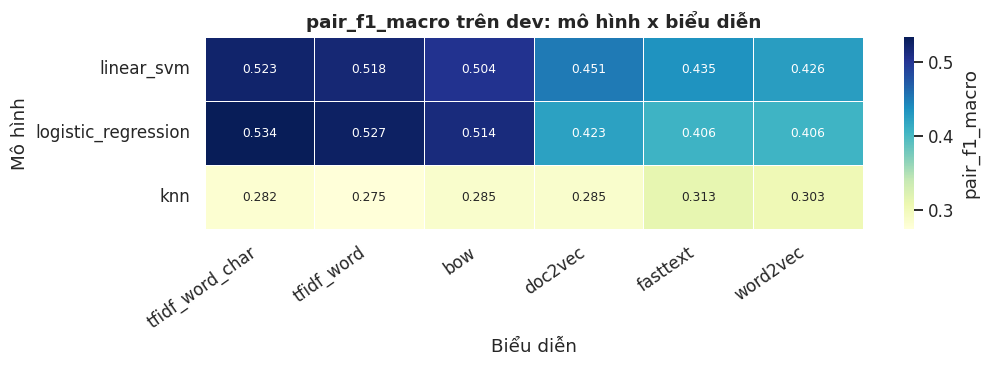

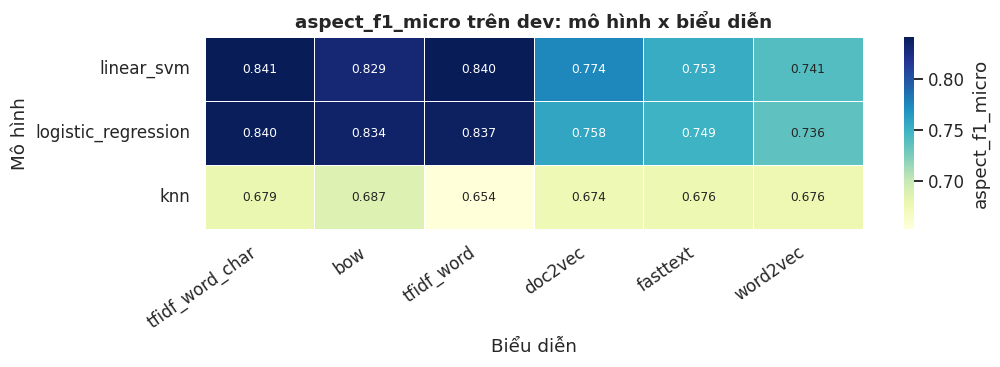

In [21]:
results = runner.results
fig = result_plots.plot_score_heatmap(results, PRIMARY_METRIC); save_figure(fig, "ml_heatmap_pair_f1_macro"); plt.show()
fig = result_plots.plot_score_heatmap(results, "aspect_f1_micro"); save_figure(fig, "ml_heatmap_aspect_f1_micro"); plt.show()

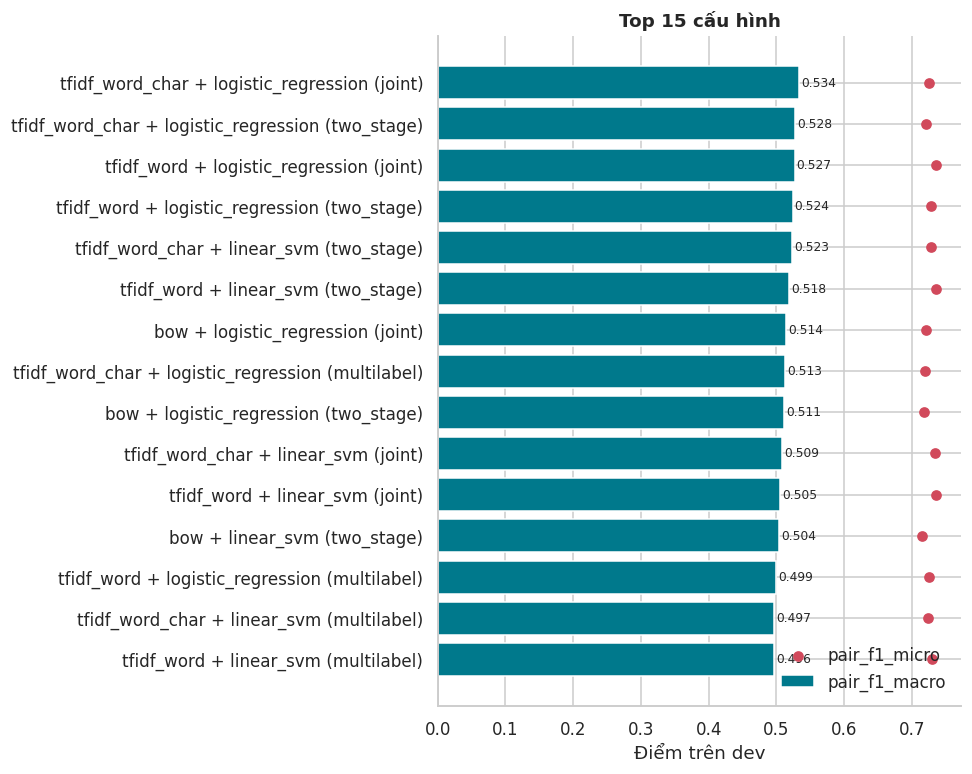

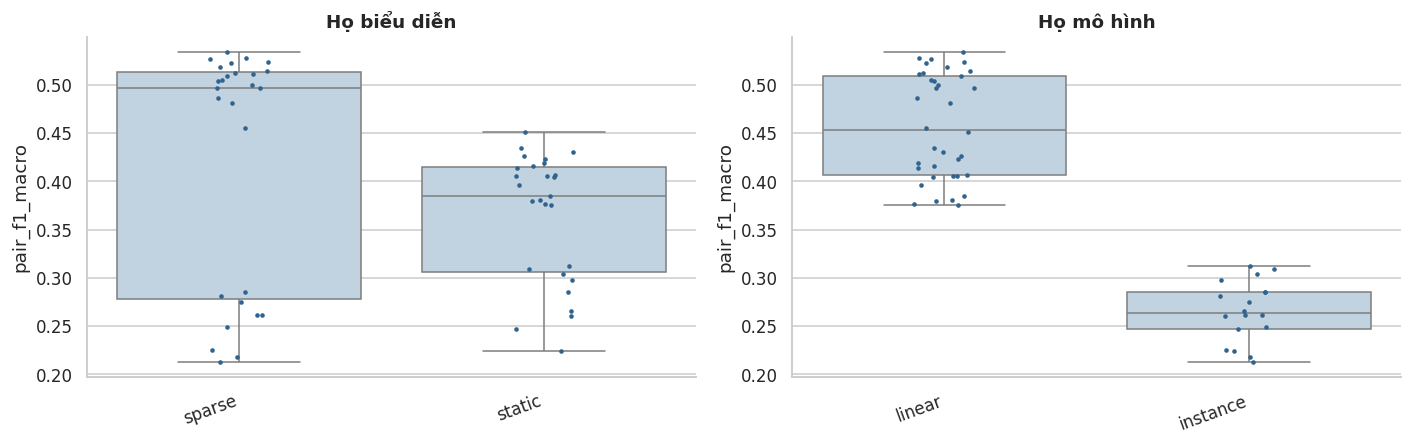

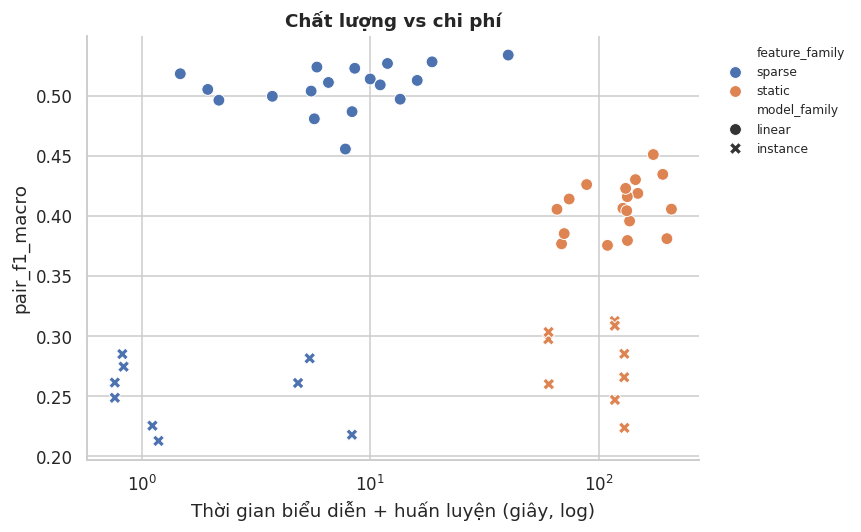

In [22]:
fig = result_plots.plot_leaderboard(runner.leaderboard(top=None)); save_figure(fig, "ml_leaderboard"); plt.show()
fig = result_plots.plot_family_comparison(results); save_figure(fig, "ml_family_comparison"); plt.show()
fig = result_plots.plot_time_vs_score(results); save_figure(fig, "ml_time_vs_score"); plt.show()

### 5.2 Thống kê kết quả: theo chiến lược, biểu diễn và mô hình

Mỗi bảng là trung bình các metric **chỉ trên các cặp có đủ mặt ở mọi nhóm** để so sánh công bằng (bỏ `majority_baseline`).

,n_pairs,pair_f1_macro,pair_f1_micro,aspect_f1_macro,aspect_f1_micro,polarity_acc_on_detected,fit_sec
strategy,,,,,,,
two_stage,18,0.4080,0.6235,0.6662,0.7528,0.8196,6.8406
joint,18,0.4017,0.6212,0.6476,0.7389,0.8332,14.4439
multilabel,18,0.3695,0.5931,0.5939,0.6850,0.8608,16.0450


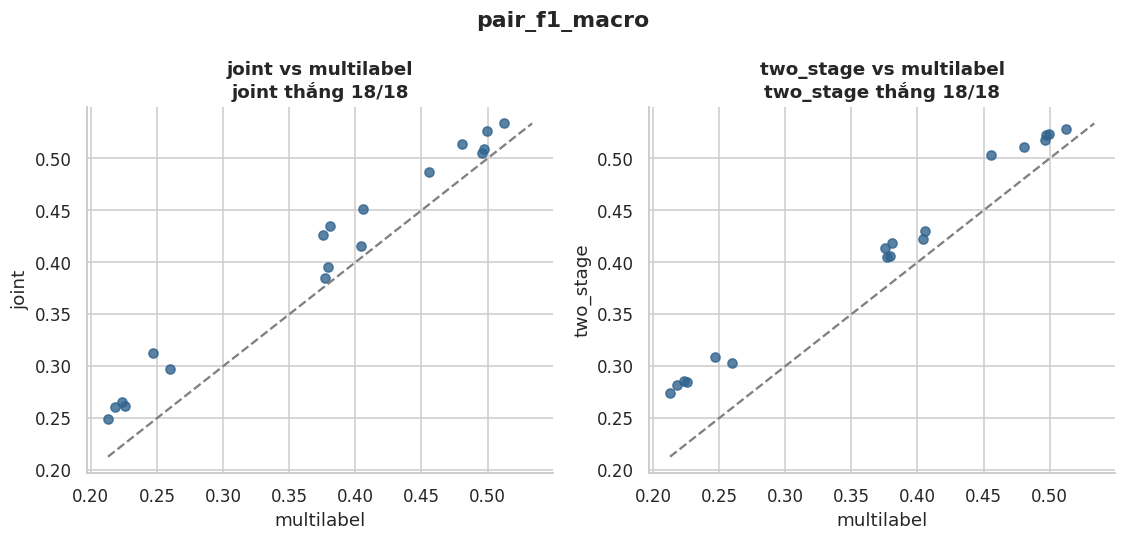

,n_pairs,pair_f1_macro,pair_f1_micro,aspect_f1_macro,aspect_f1_micro,polarity_acc_on_detected,fit_sec
feature,,,,,,,
tfidf_word_char,9,0.4293,0.6640,0.6688,0.7602,0.8699,11.2944
tfidf_word,9,0.4229,0.6635,0.6572,0.7514,0.8796,2.7789
bow,9,0.4137,0.6550,0.6574,0.7526,0.8668,4.6244
doc2vec,9,0.3672,0.5754,0.6089,0.7052,0.8118,16.7544
fasttext,9,0.3649,0.5623,0.6147,0.6954,0.8004,25.9778
word2vec,9,0.3605,0.5554,0.6084,0.6885,0.7986,13.2289


,n_pairs,pair_f1_macro,pair_f1_micro,aspect_f1_macro,aspect_f1_micro,polarity_acc_on_detected,fit_sec
model,,,,,,,
linear_svm,18,0.4573,0.6567,0.7123,0.7761,0.8357,25.9361
logistic_regression,18,0.4568,0.6405,0.7104,0.7717,0.8177,10.4833
knn,18,0.2652,0.5406,0.4849,0.6289,0.8601,0.9100


In [23]:
from absa.evaluation import summarize_by

if len(STRATEGIES) > 1:
    display(summarize_by(results, "strategy"))
    fig = result_plots.plot_strategy_comparison(results, baseline=STRATEGIES[0]); save_figure(fig, "ml_strategy"); plt.show()
display(summarize_by(results, "feature"))
display(summarize_by(results, "model"))

**Gợi ý đọc kết quả:**
- So sánh **biểu diễn** khi cố định mô hình (một hàng của heatmap, hoặc bảng `summarize_by(results, "feature")`): `bow` vs `tfidf_word` (trọng số), `tfidf_word` vs `tfidf_word_char` (n-gram ký tự có giúp không?), và nhóm sparse vs nhóm embedding đặc (`word2vec`, `fasttext`, `doc2vec`).- So sánh **chiến lược**: nhìn cả `aspect_f1_*` (phát hiện khía cạnh) lẫn `polarity_acc_on_detected` (phân cực). Trong lượt chạy thử nhỏ (2 biểu diễn TF-IDF × 5 mô hình tuyến tính/NB), trung bình macro-F1 cặp là `two_stage` 0,485 ≈ `joint` 0,482 > `multilabel` 0,457: `multilabel` kém hơn ~2,5 điểm, và `aspect_f1_macro` (phát hiện khía cạnh) cũng thấp hơn (0,701 so với 0,736 của `joint`), trong khi `polarity_acc_on_detected` lại cao hơn. Giả thuyết (chưa kiểm chứng): một khía cạnh chỉ được "phát hiện" khi một trong ba bộ phân loại cảm xúc của nó bật, mà mỗi bộ chỉ thấy rất ít mẫu dương. Hãy kiểm tra xem kết quả của bạn có giống không; chênh lệch dưới ~1 điểm nằm trong mức nhiễu của dev 1.112 câu.
- Muốn **dự đoán 31 nhãn** làm mô hình cuối thì đặt `SELECT_STRATEGY = "multilabel"` ở ô cấu hình; mô hình cuối khi đó là cấu hình `multilabel` tốt nhất, dù điểm có thể thấp hơn chiến lược khác.
- Macro-F1 cặp thấp hơn micro-F1 nhiều vì các cặp hiếm (STORAGE, `*#Neutral`).

### 5.3 Tinh chỉnh siêu tham số cho top-k cấu hình (trên dev)

In [24]:
from absa.training import tune_top_k

if RUN_TUNING:
    tuning_summary = tune_top_k(runner, k=TOP_K_TUNING)
    tuning_summary.to_csv(PATHS.reports_dir / "ml_tuning_summary.csv", index=False)
    display(tuning_summary)

04:47:41 | INFO    | absa.training.experiment | Biểu diễn tfidf_word_char         45542 chiều  (2.9s)
04:47:58 | INFO    | absa.training.experiment | tfidf_word_char        logistic_regression    joint     pair_f1_macro=0.3656 aspect_f1_micro=0.7643 (17.0s)
04:48:18 | INFO    | absa.training.experiment | tfidf_word_char        logistic_regression    joint     pair_f1_macro=0.5132 aspect_f1_micro=0.8114 (20.0s)
04:48:44 | INFO    | absa.training.experiment | tfidf_word_char        logistic_regression    joint     pair_f1_macro=0.4484 aspect_f1_micro=0.8101 (26.4s)
04:49:12 | INFO    | absa.training.experiment | tfidf_word_char        logistic_regression    joint     pair_f1_macro=0.5298 aspect_f1_micro=0.8293 (27.1s)
04:49:44 | INFO    | absa.training.experiment | tfidf_word_char        logistic_regression    joint     pair_f1_macro=0.4811 aspect_f1_micro=0.8254 (32.2s)
04:50:21 | INFO    | absa.training.experiment | tfidf_word_char        logistic_regression    joint     pair_f1_macro=

,feature,model,strategy,pair_f1_macro_default,pair_f1_macro_tuned,gain,best_params,n_candidates
0,tfidf_word_char,logistic_regression,joint,0.53373,0.53399,0.00026,"{""C"": 16.0, ""class_weight"": ""balanced""}",8
1,tfidf_word,logistic_regression,joint,0.52674,0.52988,0.00314,"{""C"": 1.0, ""class_weight"": ""balanced""}",8
2,tfidf_word_char,logistic_regression,two_stage,0.52807,0.52807,0.00000,"{""C"": 4.0, ""class_weight"": ""balanced""}",8
3,tfidf_word,logistic_regression,two_stage,0.52375,0.52488,0.00113,"{""C"": 16.0, ""class_weight"": ""balanced""}",8
4,tfidf_word_char,linear_svm,two_stage,0.52274,0.52274,0.00000,"{""C"": 0.5, ""class_weight"": ""balanced""}",10


## 6. Mô hình học sâu (tùy chọn)

Kiến trúc dùng chung **aspect heads** (mỗi khía cạnh một đầu ra), encoder thay đổi:
- TextCNN / BiLSTM + aspect attention, với embedding ngẫu nhiên / Word2Vec / FastText học trên train.
- Fine-tune Transformer: PhoBERT-base-v2, ViSoBERT, XLM-R, mDeBERTa-v3 (nên chạy trên GPU).

Early stopping theo macro-F1 cặp trên dev. Kết quả có cùng định dạng bảng với ML nên được ghép chung ở mục 7.

In [25]:
from absa.models.dl import dl_catalog

display(dl_catalog())
dl_rows, dl_histories, dl_results = [], {}, {}
if RUN_DL:
    from absa.training.dl_experiment import run_dl_experiment

    for name in DL_MODELS:
        res = run_dl_experiment(name, corpus, labels, output_dir=PATHS.reports_dir)
        dl_rows.append(res.row); dl_histories[name] = res.history; dl_results[name] = res
    pd.DataFrame(dl_rows).to_csv(PATHS.reports_dir / "dl_results.csv", index=False)
    display(pd.DataFrame(dl_rows)[["model", "feature", PRIMARY_METRIC, "pair_f1_micro", "aspect_f1_micro", "fit_sec"]])
    fig = result_plots.plot_training_history(dl_histories); save_figure(fig, "dl_history"); plt.show()

,arch,embedding / backbone,input_profile,needs_gpu,idea,reference
name,,,,,,
textcnn_random,textcnn,random,classic,False,"TextCNN, embedding khởi tạo ngẫu nhiên – mốc để thấy lợi ích embedding.","Kim (2014), EMNLP"
textcnn_word2vec,textcnn,word2vec,classic,False,"TextCNN khởi tạo bằng Word2Vec học trên train, tiếp tục fine-tune.",Kim (2014); Mikolov et al. (2013)
textcnn_fasttext,textcnn,fasttext,classic,False,TextCNN khởi tạo bằng FastText (có subword) học trên train.,Kim (2014); Bojanowski et al. (2017)
bilstm_attention_fasttext,bilstm_attention,fasttext,classic,False,"BiLSTM 2 lớp + attention riêng cho từng khía cạnh, embedding FastText.","Wang et al. (2016), EMNLP (ATAE-LSTM)"
phobert_base_v2,transformer,vinai/phobert-base-v2,transformer_seg,True,Fine-tune PhoBERT-base-v2 + aspect attention – SOTA phổ biến cho tiếng Việt.,"Nguyen & Nguyen (2020), Findings of EMNLP"
visobert,transformer,uitnlp/visobert,transformer_raw,True,Fine-tune ViSoBERT (pretrain trên mạng xã hội tiếng Việt) – hợp teencode/emoji.,"Nguyen et al. (2023), EMNLP"
xlm_roberta_base,transformer,FacebookAI/xlm-roberta-base,transformer_raw,True,Fine-tune XLM-RoBERTa-base (đa ngữ 100 ngôn ngữ).,"Conneau et al. (2020), ACL"
mdeberta_v3_base,transformer,microsoft/mdeberta-v3-base,transformer_raw,True,"Fine-tune mDeBERTa-v3-base (disentangled attention, pretrain kiểu ELECTRA).","He et al. (2023), ICLR"
phobert_large,transformer,vinai/phobert-large,transformer_seg,True,Fine-tune PhoBERT-large (370M) – mạnh nhất nhưng cần GPU >= 16GB.,"Nguyen & Nguyen (2020), Findings of EMNLP"


## 7. So sánh tổng hợp và chọn mô hình

Chọn theo `PRIMARY_METRIC` (macro-F1 trên 31 cặp khía cạnh–cảm xúc) trên dev. Bảng dưới gộp sàng lọc, tinh chỉnh và DL.

In [26]:
all_results = pd.concat([runner.results, pd.DataFrame(dl_rows)], ignore_index=True)
ok = all_results[all_results["status"] == "ok"].sort_values(PRIMARY_METRIC, ascending=False)
if SELECT_STRATEGY:  # chỉ xét các cấu hình ML của chiến lược này (DL không thuộc chiến lược nào)
    ok = ok[(ok["strategy"] == SELECT_STRATEGY) & (ok["tag"] != "dl")]
cols =["tag", "feature", "model", "strategy", "params", PRIMARY_METRIC, "pair_f1_micro",
        "aspect_f1_macro", "aspect_f1_micro", "polarity_acc_on_detected", "fit_sec"]
display(ok[cols].head(15))
all_results.to_csv(PATHS.reports_dir / "all_results.csv", index=False)

best = ok.iloc[0]
best_is_ml = best["tag"] in ("grid", "tuning")
print("Cấu hình tốt nhất:", best["feature"], "+", best["model"], f"({best['strategy']})", best["params"])
print(f"{PRIMARY_METRIC} = {best[PRIMARY_METRIC]:.4f} | pair_f1_micro = {best['pair_f1_micro']:.4f}")

,tag,feature,model,strategy,params,pair_f1_macro,pair_f1_micro,aspect_f1_macro,aspect_f1_micro,polarity_acc_on_detected,fit_sec
61,tuning,tfidf_word_char,logistic_regression,joint,"{""C"": 16.0, ""class_weight"": ""balanced""}",0.53399,0.72668,0.78239,0.83833,0.86101,34.73
19,grid,tfidf_word_char,logistic_regression,joint,{},0.53373,0.72490,0.78503,0.83978,0.85665,37.38
59,tuning,tfidf_word_char,logistic_regression,joint,"{""C"": 4.0, ""class_weight"": ""balanced""}",0.53373,0.72490,0.78503,0.83978,0.85665,36.91
73,tuning,tfidf_word,logistic_regression,joint,"{""C"": 1.0, ""class_weight"": ""balanced""}",0.52988,0.71890,0.76868,0.82345,0.86641,9.23
57,tuning,tfidf_word_char,logistic_regression,joint,"{""C"": 1.0, ""class_weight"": ""balanced""}",0.52981,0.71214,0.77830,0.82934,0.85146,27.13
20,grid,tfidf_word_char,logistic_regression,two_stage,{},0.52807,0.72154,0.79125,0.83932,0.85289,15.87
67,tuning,tfidf_word_char,logistic_regression,two_stage,"{""C"": 4.0, ""class_weight"": ""balanced""}",0.52807,0.72154,0.79125,0.83932,0.85289,16.44
10,grid,tfidf_word,logistic_regression,joint,{},0.52674,0.73629,0.78058,0.83711,0.87370,11.35
75,tuning,tfidf_word,logistic_regression,joint,"{""C"": 4.0, ""class_weight"": ""balanced""}",0.52674,0.73629,0.78058,0.83711,0.87370,11.43
85,tuning,tfidf_word,logistic_regression,two_stage,"{""C"": 16.0, ""class_weight"": ""balanced""}",0.52488,0.73340,0.78490,0.83959,0.86800,6.12


Cấu hình tốt nhất: tfidf_word_char + logistic_regression (joint) {"C": 16.0, "class_weight": "balanced"}
pair_f1_macro = 0.5340 | pair_f1_micro = 0.7267


## 8. Đánh giá chi tiết mô hình tốt nhất trên dev

,support,detect_precision,detect_recall,detect_f1,sentiment_f1_macro,polarity_acc_on_detected
aspect,,,,,,
SCREEN,121,0.715,0.769,0.741,0.534,0.871
CAMERA,296,0.915,0.912,0.914,0.629,0.796
FEATURES,381,0.889,0.822,0.854,0.559,0.850
BATTERY,504,0.960,0.954,0.957,0.666,0.854
PERFORMANCE,582,0.879,0.857,0.868,0.569,0.834
STORAGE,14,0.462,0.429,0.444,0.185,0.833
DESIGN,187,0.821,0.759,0.789,0.474,0.908
PRICE,252,0.892,0.921,0.906,0.677,0.793
GENERAL,689,0.839,0.846,0.842,0.621,0.931


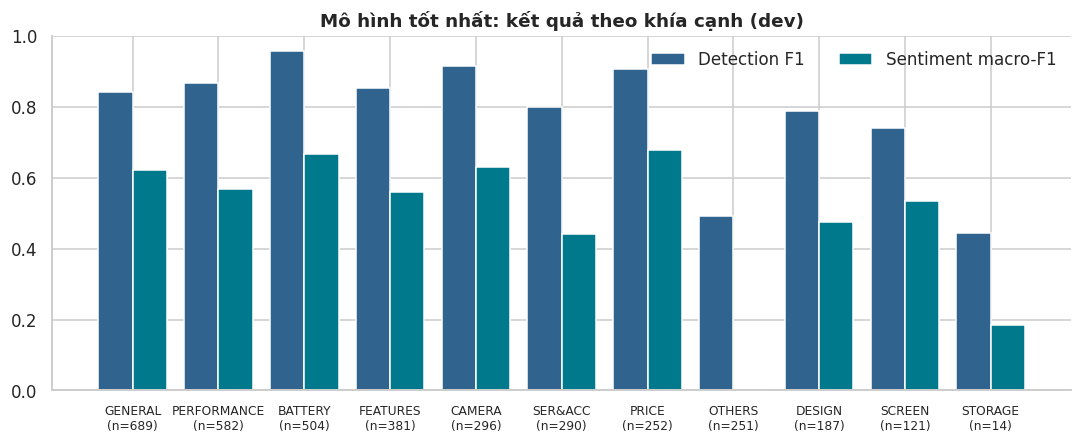

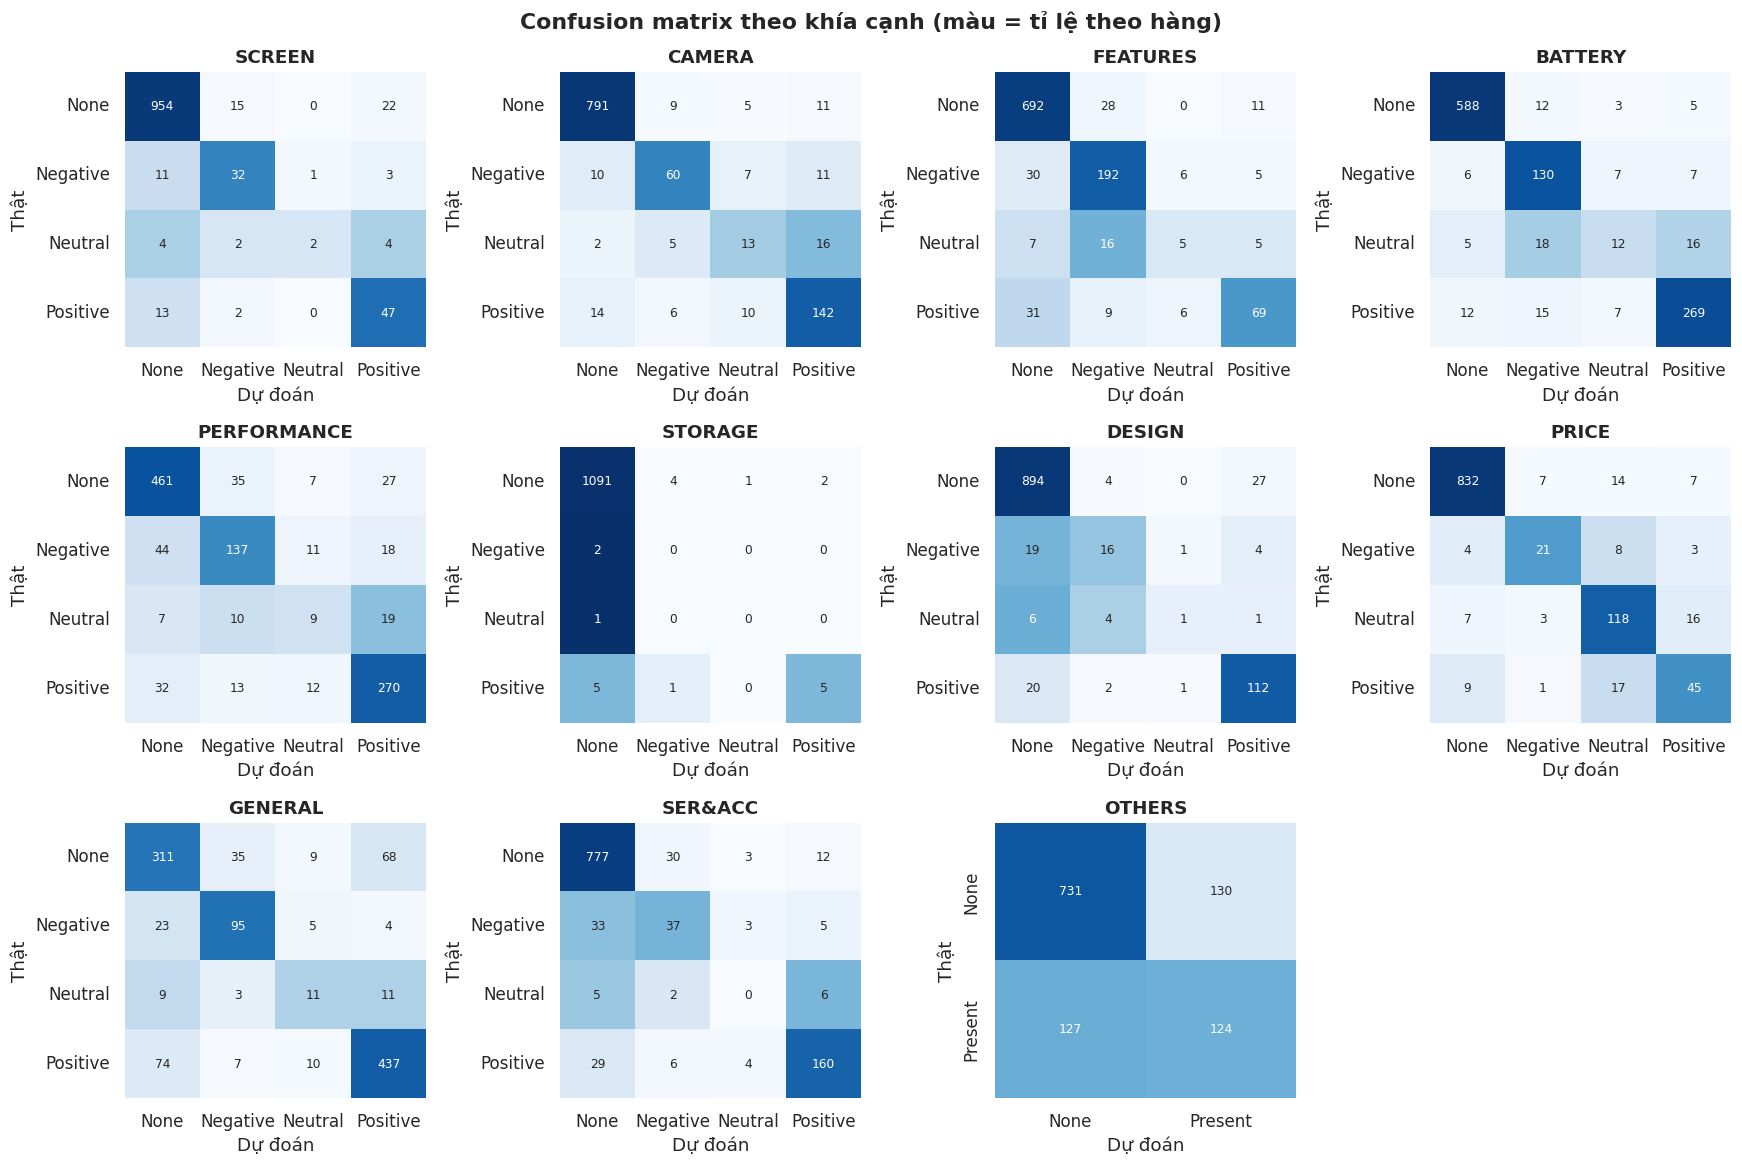

,precision,recall,f1,support
SCREEN#Negative,0.627,0.681,0.653,47
SCREEN#Neutral,0.667,0.167,0.267,12
SCREEN#Positive,0.618,0.758,0.681,62
CAMERA#Negative,0.750,0.682,0.714,88
CAMERA#Neutral,0.371,0.361,0.366,36
CAMERA#Positive,0.789,0.826,0.807,172
FEATURES#Negative,0.784,0.824,0.803,233
FEATURES#Neutral,0.294,0.152,0.200,33
FEATURES#Positive,0.767,0.600,0.673,115
BATTERY#Negative,0.743,0.867,0.800,150


In [27]:
from absa.evaluation import all_confusion_matrices, pair_report, per_aspect_report

if best_is_ml:
    Y_dev_pred = runner.predictions.get(best["run_id"])
    if Y_dev_pred is None:  # Kết quả nạp từ CSV ở phiên trước: chạy lại cấu hình này.
        import json
        runner.run(best["feature"], best["model"], best["strategy"], json.loads(best["params"]), tag=best["tag"])
        Y_dev_pred = runner.predictions[best["run_id"]]
else:
    Y_dev_pred = dl_results[best["model"]].predictions

aspect_report = per_aspect_report(dev.labels, Y_dev_pred)
display(aspect_report.round(3))
fig = result_plots.plot_per_aspect(aspect_report, "Mô hình tốt nhất: kết quả theo khía cạnh (dev)"); save_figure(fig, "best_per_aspect"); plt.show()
fig = result_plots.plot_confusion_grid(all_confusion_matrices(dev.labels, Y_dev_pred)); save_figure(fig, "best_confusion_grid"); plt.show()
display(pair_report(dev.labels, Y_dev_pred).round(3))

### 8.1 Dự đoán thô 31 nhãn của chiến lược `multilabel` và mức xung đột

Với `multilabel`, mỗi nhãn được dự đoán độc lập nên một khía cạnh có thể bị bật **nhiều cảm xúc cùng lúc** (vd `BATTERY#Negative` và `BATTERY#Positive`). Bảng dưới đo mức xung đột đó và so điểm **thô** (31 bit, chưa xử lý) với điểm **sau giải mã** (mỗi khía cạnh một cảm xúc).

In [28]:
import json as _json

from absa.data import count_pair_conflicts, pair_label_names, to_pair_matrix
from absa.evaluation import evaluate_absa, evaluate_pair_bits, pair_report_from_bits

if best_is_ml and best["strategy"] == "multilabel":
    pairs_raw = runner.fit_predict_pairs(best["feature"], best["model"], _json.loads(best["params"]))
    pairs_true = to_pair_matrix(dev.labels)
    print("Dự đoán thô:", pairs_raw.shape, "-> 31 nhãn:", pair_label_names()[:3], "...")
    display(pd.Series(count_pair_conflicts(pairs_raw), name="xung đột").to_frame().T)
    compare = pd.DataFrame({
        "31 bit thô (chưa xử lý xung đột)": evaluate_pair_bits(pairs_true, pairs_raw),
        "sau giải mã (1 cảm xúc / khía cạnh)": {k: v for k, v in evaluate_absa(dev.labels, Y_dev_pred).items() if k.startswith("pair_")},
    })
    display(compare.round(4))
    raw_report = pair_report_from_bits(pairs_true, pairs_raw).round(3)
    display(raw_report.sort_values("f1"))
else:
    print("Mô hình tốt nhất không dùng chiến lược multilabel - bỏ qua mục này.")

Mô hình tốt nhất không dùng chiến lược multilabel - bỏ qua mục này.


## 9. Phân tích lỗi (trên dự đoán out-of-fold của train)

Phân tích lỗi cần **đọc văn bản**, nên làm trên train bằng 5-fold cross-validation: mỗi câu được dự đoán bởi mô hình chưa từng thấy nó. Dev vẫn giữ sạch. Chỉ khi đặt `INSPECT_DEV_TEXT = True` (sau khi đã chốt mô hình) mới xem lỗi trên dev.

04:56:44 | INFO    | absa.training.cross_validation | Fold 1/5 xong
04:57:10 | INFO    | absa.training.cross_validation | Fold 2/5 xong
04:57:40 | INFO    | absa.training.cross_validation | Fold 3/5 xong
04:58:10 | INFO    | absa.training.cross_validation | Fold 4/5 xong
04:58:40 | INFO    | absa.training.cross_validation | Fold 5/5 xong


,train OOF
aspect_precision_micro,0.8379
aspect_recall_micro,0.8216
aspect_f1_micro,0.8296
aspect_precision_macro,0.8050
aspect_recall_macro,0.7648
aspect_f1_macro,0.7820
pair_precision_micro,0.7221
pair_recall_micro,0.7081
pair_f1_micro,0.7151
pair_precision_macro,0.5596


,support,missed,spurious,polarity,total_errors
aspect,,,,,
OTHERS,1694,955,1001,0,1956
GENERAL,4866,828,841,271,1940
PERFORMANCE,4140,587,493,562,1642
FEATURES,2642,459,345,343,1147
BATTERY,3604,234,159,586,979
SER&ACC,1995,419,296,132,847
PRICE,2061,246,226,367,839
CAMERA,2146,179,182,403,764
DESIGN,1378,353,248,113,714


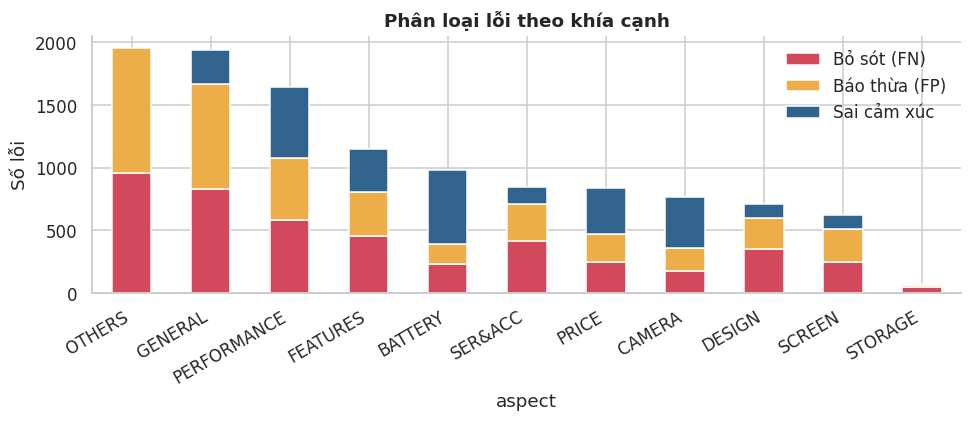

,count
true -> predicted,
Neutral -> Positive,681
Neutral -> Negative,524
Positive -> Negative,487
Positive -> Neutral,446
Negative -> Positive,443
Negative -> Neutral,320


,text,processed,true,pred,missed,spurious,polarity,n_errors
index,,,,,,,,
5047,"Mình mua trả gộp 0% lãi suất xét hồ sơ tại shop, mất 20 phút, cùng tắm gội là nhanh. Ban đầu tình mua A51 những sau ...",mình mua trả gộp numpercent lãi suất xét hồ sơ tại shop mất numduration cùng tắm gội là nhanh ban đầu tình mua a51 n...,{SCREEN#Positive};{PERFORMANCE#Positive};{PRICE#Positive};{GENERAL#Positive};{SER&ACC#Positive};,{PERFORMANCE#Positive};{GENERAL#Negative};{OTHERS};,"SCREEN, PRICE, SER&ACC",OTHERS,GENERAL,5
7751,Với tầm giá này thì nó đem lại trải nghiệm khá tốt mặc dù chỉ hơn 2tr500k thôi kkk,với tầm giá này thì nó đem lại trải nghiệm khá tốt mặc dù chỉ hơn num tr500k thôi emopos,{PRICE#Positive};{GENERAL#Positive};,{PRICE#Neutral};{GENERAL#Positive};,,,PRICE,1
842,Điện thoại sài rất tốt nhưng lâu lâu cũng xuất hiện nhiều lỗi nhưng cho mình hỏi về vấn đề pin là lúc tối là điện th...,điện thoại xài rất tốt nhưng lâu lâu cũng xuất hiện nhiều lỗi nhưng cho mình hỏi về vấn đề pin là lúc tối là điện th...,{BATTERY#Neutral};{PERFORMANCE#Negative};{GENERAL#Positive};,{BATTERY#Negative};{GENERAL#Positive};,PERFORMANCE,,BATTERY,2
5603,"Nhận máy hqa, thấy các bạn nói pin trâu, nhưng mình thấy máy của mình thì pin yếu quá, mọi thứ khác thì ok",nhận máy hqa thấy các bạn nói pin trâu nhưng mình thấy máy của mình thì pin yếu quá mọi thứ khác thì ok,{BATTERY#Negative};{GENERAL#Positive};,{BATTERY#Positive};{GENERAL#Positive};,,,BATTERY,1
7785,Mình rất thất vọng khi mua máy này. Bắt wifi cực kì yếu..😪😪 vẫn là samsung dùng ngon nhất.,mình rất thất vọng khi mua máy này bắt wifi cực kì yếu emoneg vẫn là samsung dùng ngon nhất,{FEATURES#Negative};{GENERAL#Negative};{SER&ACC#Negative};,{FEATURES#Positive};{GENERAL#Negative};{SER&ACC#Negative};,,,FEATURES,1
4315,"*Mua được gần 1 tháng 25 ngày \r\n -Theo đánh giá: \r\n + chơi game ổn, mấy tựa game nặng nên chơi cấu hình ...",mua được gần numduration numduration theo đánh giá chơi game ổn mấy tựa game nặng nên chơi cấu hình thấp thôi mấy ba...,{SCREEN#Positive};{CAMERA#Positive};{FEATURES#Positive};{BATTERY#Neutral};{PERFORMANCE#Neutral};{DESIGN#Positive};{P...,{CAMERA#Positive};{FEATURES#Positive};{BATTERY#Positive};{PERFORMANCE#Neutral};{DESIGN#Positive};{PRICE#Neutral};{GE...,SCREEN,OTHERS,BATTERY,3
5175,Tôi dùng được khoảng 2 tháng mọi thứ đều tạm ổn dùng wifi để chơi FB hay các mxh khác đều ok trước kia khi chơi game...,tôi dùng được khoảng numduration mọi thứ đều tạm ổn dùng wifi để chơi facebook hay các mxh khác đều ok trước kia khi...,{FEATURES#Negative};{PERFORMANCE#Negative};{GENERAL#Neutral};{OTHERS};,{FEATURES#Negative};{PERFORMANCE#Neutral};{GENERAL#Positive};,OTHERS,,"PERFORMANCE, GENERAL",3
1915,Sản phẩm ổn trong tầm giá..sản phẩm đẹp sang trọng ít nóng máy. Có điều bin 4030 nhưng nhanh hết qua.,sản phẩm ổn trong tầm giá sản phẩm đẹp sang trọng ít nóng máy có điều pin num nhưng nhanh hết qua,{BATTERY#Negative};{PERFORMANCE#Positive};{DESIGN#Positive};{PRICE#Neutral};{GENERAL#Positive};,{BATTERY#Negative};{PERFORMANCE#Neutral};{DESIGN#Positive};{PRICE#Neutral};{GENERAL#Positive};,,,PERFORMANCE,1


,text,processed,true,pred,missed,spurious,polarity,n_errors
index,,,,,,,,
545,"Máy xài không có gì phàn nàn, chỉ mỗi tội sau 3 tháng bị hư GPS phải đi bảo hành, Chán!",máy xài không_có_gì phàn nàn chỉ mỗi tội sau numduration bị hư gps phải đi bảo hành chán,{FEATURES#Negative};{GENERAL#Neutral};,{DESIGN#Negative};{GENERAL#Negative};,FEATURES,DESIGN,GENERAL,3
1953,Máy màu xanh lá đậm khá oke.chup ảnh biết canh góc là bao đẹp. Pin xài mượt 4000 mà đc 1 ngày rưỡi . Sạc nhanh tầm ...,máy màu xanh lá đậm khá ok chup ảnh biết canh góc là bao đẹp pin xài mượt num mà được numduration rưỡi sạc nhanh tầm...,{CAMERA#Positive};{FEATURES#Positive};{BATTERY#Positive};{PRICE#Positive};{GENERAL#Positive};{SER&ACC#Positive};,{CAMERA#Positive};{BATTERY#Positive};{DESIGN#Positive};{GENERAL#Positive};{SER&ACC#Positive};,"FEATURES, PRICE",DESIGN,,3
5294,Lâu lâu máy tự có chuông kêu mà bấm xem k có gì cả bị sao v nhỉ. Chỉ tiếc chân sạc nếu lỡ quên hay hpin thì khos mượ...,lâu lâu máy tự có chuông kêu mà bấm xem không_có_gì cả bị sao v nhỉ chỉ tiếc chân sạc nếu lỡ quên hay hpin thì khos ...,{FEATURES#Negative};{DESIGN#Negative};,{BATTERY#Negative};{DESIGN#Negative};,FEATURES,BATTERY,,2
7779,"Máy quá tệ luôn , mới lấy tức thì , ý định mua về để có thể lướt web và lên YouTube để sử dụng beat vs lấy nhạc. , a...",máy quá tệ luôn mới lấy tức thì ý định mua về để có thể lướt web và lên youtube để sử dụng beat với lấy nhạc ai ngờ ...,{FEATURES#Negative};{GENERAL#Negative};,{PERFORMANCE#Negative};{GENERAL#Negative};{OTHERS};,FEATURES,"PERFORMANCE, OTHERS",,3
3225,Camera chụp đêm cực mờ dù đã hiệu chỉnh các kiểu.nhận diện khuôn mặt lúc được luac không.ghét mỗi 2 điểm này còn lại...,camera chụp đêm cực mờ dù đã hiệu chỉnh các kiểu nhận diện khuôn mặt lúc được luac không ghét mỗi num điểm này còn l...,{CAMERA#Negative};{FEATURES#Negative};,{CAMERA#Positive};{GENERAL#Neutral};,FEATURES,GENERAL,CAMERA,3
1744,"Mọi thứ oki,nhug video gọi Zalo ko có flash, cả trc với sau.pin trâu, máy to cầm giữ hơi khó",mọi thứ ok nhug video gọi zalo không_có_flash cả trước với sau pin trâu máy to cầm giữ hơi khó,{FEATURES#Negative};{BATTERY#Positive};{DESIGN#Negative};{GENERAL#Positive};,{BATTERY#Positive};{GENERAL#Positive};,"FEATURES, DESIGN",,,2
5292,Máy dùng chủ yếu nhắn tin. Nhưng ấn nhập nhằng mãi mới đc. Khi chơi game thì ấn tức không chịu được. Quảng cáo thì h...,máy dùng chủ yếu nhắn tin nhưng ấn nhập nhằng mãi mới được khi chơi game thì ấn tức không_chịu được quảng cáo thì ha...,{FEATURES#Negative};{GENERAL#Negative};,{PERFORMANCE#Negative};{GENERAL#Negative};,FEATURES,PERFORMANCE,,2
1108,Cả nha cho em xin chút ý kiến khi mua 71 . Chơi liên quân có bị đơ máy không. Âm thanh như thế nào. Camera nét không...,cả nha cho em xin chút ý kiến khi mua num chơi liên quân có bị đơ máy không âm thanh như thế nào camera nét không pi...,{CAMERA#Neutral};{FEATURES#Neutral};{PERFORMANCE#Neutral};{PRICE#Negative};{OTHERS};,{BATTERY#Positive};{PERFORMANCE#Positive};{OTHERS};,"CAMERA, FEATURES, PRICE",BATTERY,PERFORMANCE,5


In [29]:
import json

from absa.evaluation import build_error_table, error_type_summary, polarity_confusions, sample_errors
from absa.features import get_feature_spec
from absa.training import cross_val_predict_absa

if RUN_ERROR_ANALYSIS and best_is_ml:
    profile = get_feature_spec(best["feature"]).profile
    Y_oof = cross_val_predict_absa(
        corpus.get(profile, "train"), train.labels, best["feature"], best["model"],
        best["strategy"], json.loads(best["params"]), n_jobs=N_JOBS,
    )
    from absa.evaluation import evaluate_absa
    display(pd.Series(evaluate_absa(train.labels, Y_oof)).round(4).to_frame("train OOF"))
    summary = error_type_summary(train.labels, Y_oof)
    display(summary)
    fig = result_plots.plot_error_types(summary); save_figure(fig, "error_types"); plt.show()
    display(polarity_confusions(train.labels, Y_oof))
    errors = build_error_table(train.texts, train.labels, Y_oof, corpus.get(profile, "train"))
    errors.to_csv(PATHS.reports_dir / "error_table_train_oof.csv")
    display(sample_errors(errors, kind="polarity", n=8))
    display(sample_errors(errors, aspect="FEATURES", kind="missed", n=8))

**Khung ghi nhận xét lỗi (điền sau khi chạy):**
1. *Nhầm Neutral ↔ Positive/Negative*: câu so sánh tầm giá (`ổn trong tầm giá`) hoặc điều kiện (`pin trâu nếu để độ sáng vừa`).
2. *Bỏ sót khía cạnh ngầm*: khía cạnh được ám chỉ, không nêu tên (`nóng máy` → BATTERY/PERFORMANCE).
3. *Báo thừa GENERAL*: câu khen chung chung trùng từ vựng với khen khía cạnh cụ thể.
4. *Mơ hồ trong nhãn*: chỉ ra các trường hợp chính nhãn gốc còn tranh cãi.

In [30]:
if INSPECT_DEV_TEXT:
    dev_errors = build_error_table(dev.texts, dev.labels, Y_dev_pred)
    display(sample_errors(dev_errors, n=10))

## 10. Mô hình cuối: huấn luyện lại trên train + dev và đánh giá test ẩn

1. Huấn luyện lại cấu hình đã chọn trên **train + dev** (dev đã xong vai trò chọn mô hình).
2. Nếu có `Test.csv`: đánh giá **một lần**, ghi kết quả, **không quay lại chỉnh sửa** sau khi đã thấy điểm test.

In [31]:
from absa.training import fit_final_pipeline

if best_is_ml:
    final_pipeline = fit_final_pipeline(
        corpus, labels, best["feature"], best["model"], best["strategy"], best["params"],
        fit_splits=("train", "dev"), n_jobs=N_JOBS,
        extra_metadata={"selection_metric": PRIMARY_METRIC, "dev_score": float(best[PRIMARY_METRIC])},
    )
    display(pd.Series(final_pipeline.metadata, dtype=object).to_frame("value"))
else:
    final_pipeline = None
    print("Mô hình tốt nhất là DL: dùng dl_results[best['model']].trainer để đóng gói (xem mục 11).")

04:59:24 | INFO    | absa.training.final | Huấn luyện mô hình cuối trên ('train', 'dev') (8898 mẫu) trong 43.1s


,value
feature,tfidf_word_char
model,logistic_regression
strategy,joint
params,"{'C': 16.0, 'class_weight': 'balanced'}"
preprocess_profile,classic
preprocess_config,"{'normalize_unicode': True, 'remove_urls': True, 'emoji_mode': 'tag', 'emoticon_mode': 'tag', 'lowercase': True, 'no..."
fit_splits,"[train, dev]"
n_train,8898
fit_seconds,43.1
created_at,2026-10-14T04:59:24


In [32]:
from absa.evaluation import evaluate_absa

if test is not None and final_pipeline is not None:
    Y_test_pred = final_pipeline.predict(test.texts)
    test_metrics = evaluate_absa(test.labels, Y_test_pred)
    save_json(test_metrics, PATHS.reports_dir / "test_metrics.json")
    display(pd.Series(test_metrics).round(4).to_frame("test"))
    display(per_aspect_report(test.labels, Y_test_pred).round(3))
else:
    print("Test đang bị ẩn – bỏ qua. Khi có Test.csv trong UIT-ViSFD/, chạy lại riêng cell này.")

Test đang bị ẩn – bỏ qua. Khi có Test.csv trong UIT-ViSFD/, chạy lại riêng cell này.


## 11. Đóng gói và triển khai

`ABSAPipeline` gói *bộ tiền xử lý + biểu diễn + mô hình + metadata* vào **một file**. Demo:

```bash
streamlit run app/streamlit_app.py
```

,comment,SCREEN,CAMERA,FEATURES,BATTERY,PERFORMANCE,STORAGE,DESIGN,PRICE,GENERAL,SER&ACC,OTHERS,label
0,"Máy đẹp, pin trâu, chơi liên quân mượt. Tuy nhiên camera chụp tối hơi nhòe.",,Negative,,Positive,Positive,,Positive,,,,,{CAMERA#Negative};{BATTERY#Positive};{PERFORMANCE#Positive};{DESIGN#Positive};
1,"Mới mua 2 tuần đã bị lỗi cảm ứng, mang ra bảo hành thì nhân viên thái độ kém :((",,,Negative,,,,,,,Negative,,{FEATURES#Negative};{SER&ACC#Negative};
2,"Giá 5tr mà cấu hình vậy là ok rồi, loa hơi nhỏ",,,Negative,,Neutral,,,Neutral,,,,{FEATURES#Negative};{PERFORMANCE#Neutral};{PRICE#Neutral};
3,"sp tốt, giao hàng nhanh, đóng gói cẩn thận 👍👍",,,,,,,,,Positive,Positive,,{GENERAL#Positive};{SER&ACC#Positive};


,mentions,Negative,Neutral,Positive,pct_negative,pct_neutral,pct_positive,net_score
aspect,,,,,,,,
GENERAL,690,129,34,527,18.7,4.9,76.4,57.7
PERFORMANCE,585,210,45,330,35.9,7.7,56.4,20.5
BATTERY,505,151,51,303,29.9,10.1,60.0,30.1
FEATURES,383,234,33,116,61.1,8.6,30.3,-30.8
CAMERA,300,89,36,175,29.7,12.0,58.3,28.7
SER&ACC,291,79,13,199,27.1,4.5,68.4,41.2
PRICE,254,36,144,74,14.2,56.7,29.1,15.0
DESIGN,188,40,12,136,21.3,6.4,72.3,51.1
SCREEN,124,47,12,65,37.9,9.7,52.4,14.5


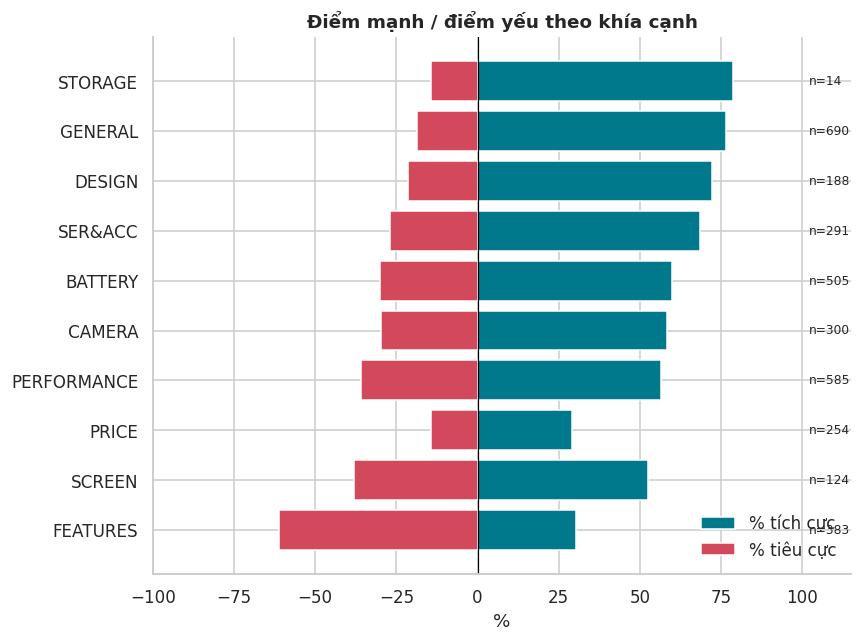

In [33]:
from absa.inference import ABSAPipeline

MODEL_PATH = PATHS.models_dir / "best_ml_pipeline.joblib"
if final_pipeline is not None:
    final_pipeline.save(MODEL_PATH)
    loaded = ABSAPipeline.load(MODEL_PATH)
    new_reviews = [
        "Máy đẹp, pin trâu, chơi liên quân mượt. Tuy nhiên camera chụp tối hơi nhòe.",
        "Mới mua 2 tuần đã bị lỗi cảm ứng, mang ra bảo hành thì nhân viên thái độ kém :((",
        "Giá 5tr mà cấu hình vậy là ok rồi, loa hơi nhỏ",
        "sp tốt, giao hàng nhanh, đóng gói cẩn thận 👍👍",
    ]
    display(loaded.predict_frame(new_reviews))
    if loaded.metadata.get("strategy") == "multilabel":
        pairs_new = loaded.predict_pairs(new_reviews)  # 31 nhãn nhị phân thô
        display(pairs_new.T.loc[lambda d: d.sum(axis=1) > 0].rename(columns=lambda i: f"review {i}"))
    summary = loaded.summarize(dev.texts)  # minh họa tổng hợp trên một tập bình luận
    display(summary)
    fig = result_plots.plot_product_summary(summary); save_figure(fig, "deploy_product_summary"); plt.show()

## 12. Kết luận và hướng phát triển

- **Tóm tắt kết quả**: cấu hình tốt nhất (biểu diễn sparse nào, mô hình nào, chiến lược nào), tác dụng của bigram/trigram và n-gram ký tự, so sánh `multilabel`/`joint`/`two_stage`.
- **Tiền xử lý**: những bước có đóng góp dương rõ ràng theo ablation.
- **Hạn chế**: khía cạnh hiếm (STORAGE), nhãn Neutral, khía cạnh ngầm; Binary Relevance bỏ qua tương quan giữa các nhãn.
- **Hướng phát triển**: Classifier Chains (khai thác tương quan nhãn); fine-tune PhoBERT/ViSoBERT trên GPU; tinh chỉnh ngưỡng quyết định theo từng nhãn trên dev; tăng cường dữ liệu cho khía cạnh hiếm.

## 13. Xuất kết quả (tải về từ Colab)

Gói bảng kết quả, hình vẽ, dữ liệu đã tiền xử lý và mô hình thành một file zip. Trên Colab, file được tải về máy; nhớ làm bước này trước khi runtime bị ngắt vì `/content` là bộ nhớ tạm.

In [34]:
export_path = ROOT / "absa_outputs.zip"
with zipfile.ZipFile(export_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(PATHS.outputs_dir.rglob("*")):
        if path.is_file() and "cache" not in path.relative_to(PATHS.outputs_dir).parts:
            archive.write(path, path.relative_to(PATHS.outputs_dir))  # bỏ cache (nặng, tính lại được)
print("Đã tạo:", export_path, f"({export_path.stat().st_size / 1e6:.1f} MB)")
if IN_COLAB:
    from google.colab import files

    files.download(str(export_path))

Đã tạo: /content/absa-visfd/absa_outputs.zip (18.5 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>